# L2-ARCTIC Mispronunciation Detection & Diagnosis (L2-MDD) — Enhanced Training & Thesis Evaluation

**Setup on Kaggle:**
1. **Add Data:** `tnguynthnh142/l2-arctic1` (`ABA/ABA/wav/` layout)
2. **Settings:** Accelerator `GPU T4` + `Internet ON`
3. **Run All**

**Upgrades in this version:**
- **Full 6-Module WavLM LoRA Adaptation:** Expands LoRA targets from FFN-only (`intermediate_dense`, `output_dense`) to all 6 transformer linear layers (`q_proj`, `k_proj`, `v_proj`, `out_proj`, `intermediate_dense`, `output_dense`, `r=8`, `lora_alpha=16`, `lora_dropout=0.10`), 100% auto-detected by `L2MDDPredictor` in `infer/pronunciation.py`.
- **Strict Speaker-Disjoint Train / Val / Test Split:** Trains on 15 speakers, validates & early-stops on 3 held-out unseen speakers (`SKA`, `NCC`, `ERMS` across distinct L1s), and keeps the 6 standard test speakers (`ZHAA`, `TXHC`, `TNI`, `YKWK`, `NJS`, `TLV` = 900 utterances) 100% isolated until final evaluation.
- **Anti-Overfitting & Precision/FAR Calibration:** Adds `label_smoothing=0.04` to weighted Focal `MDDLoss` with smoother class weights `(N_0/N_c)^0.45` clamped `[1.0, 5.5]`, `dropout=0.25`, `weight_decay=0.03`, train-only SNR-safe waveform augmentation, short-span SpecAugment (`mask_time_length=4`), parameter-free feature channel dropout, and `EMA (decay=0.998)`.
- **Speed & Efficiency:** Pre-cached `float16` RAM audio + length-bucketed batching + `fp16` AMP during train/val/test.
- **Clean Output Artifacts:** Saves **only the single best checkpoint** (`/kaggle/working/l2_mdd_best.pt`) selected by `0.65 * Det_F1 + 0.35 * Macro_F1`, and exports 4 high-DPI (300 DPI) thesis figures + L1/speaker/threshold reports in `/kaggle/working/reports_l2_mdd/`.


In [1]:
!pip uninstall -y -q torchao
!pip install -q transformers torchaudio torch-geometric peft tqdm textgrid scipy scikit-learn pandas matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 17.9 MB/s eta 0:00:00


In [2]:
# Bypass compatibility conflict between legacy torchao on Kaggle and recent PEFT
try:
    import peft.import_utils
    peft.import_utils.is_torchao_available = lambda: False
except Exception:
    pass

import json
import os
import random
import re
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, Sampler
from tqdm import tqdm

CONFIG = {
    "wavlm": {
        "model_name": "microsoft/wavlm-large",
        "freeze": True,
        "use_lora": True,
        "lora_r": 8,
        "lora_alpha": 16,
        "lora_dropout": 0.10,
        "lora_target_modules": [
            "q_proj",
            "k_proj",
            "v_proj",
            "out_proj",
            "intermediate_dense",
            "output_dense",
        ],
        "layerdrop": 0.05,
        "mask_time_prob": 0.05,
        "mask_time_length": 4,
        "mask_time_min_masks": 1,
        "mask_feature_prob": 0.0,
        "mask_feature_length": 16,
    },
    "transformer": {
        "num_layers": 3,
        "num_heads": 8,
        "ff_dim": 2048,
        "dropout": 0.25,
        "max_seq_len": 800,
    },
    "ctc_align": {"use_wavlm_ctc_head": True},
    "phoneme_graph": {
        "hidden_dim": 256,
        "num_gat_layers": 2,
        "num_heads": 4,
        "dropout": 0.25,
        "edge_types": {"sequential": True, "same_word": True, "same_syllable": False},
    },
    "mdd": {
        "num_classes": 4,
        "dropout": 0.25,
        "canon_emb_dim": 256,
        "class_weights": None,  # Auto: (N_0 / N_c)^0.45 clamped [1.0, 5.5]
        "weight_exponent": 0.45,
        "max_class_weight": 5.5,
        "focal_gamma": 1.5,
        "label_smoothing": 0.04,
    },
    "paths": {
        "best_checkpoint": "/kaggle/working/l2_mdd_best.pt",
        "report_dir": "/kaggle/working/reports_l2_mdd",
    },
    "train": {
        "seed": 42,
        "batch_size": 4,
        "grad_accum_steps": 4,
        "num_epochs": 28,
        "learning_rate": 1.2e-4,
        "learning_rate_wavlm": 3.5e-5,
        "weight_decay": 0.03,
        "warmup_epochs": 2,
        "early_stopping_patience": 6,
        "grad_clip": 1.0,
        "ctc_weight": 0.50,
        "ema_decay": 0.998,
        "feature_dropout_p": 0.12,
        "cache_audio_in_ram": True,
        "max_ram_cache_mb": 2048,
        "augment_train": True,
        "num_workers": 0,
        "pin_memory": True,
        "use_amp": True,
        "save_every_epochs": 0,
        "dataset": {"data_dir": None, "max_duration_sec": 10.0, "sample_rate": 16000},
    },
}


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


KAGGLE_ROOT = Path("/kaggle/input/datasets/tnguynthnh142/l2-arctic1")
PROBE = ("ABA", "TLV", "NJS")

SPEAKER_TO_L1: Dict[str, str] = {
    "ABA": "Arabic", "SKA": "Arabic", "YBAA": "Arabic", "ZHAA": "Arabic",
    "BWC": "Chinese", "LXC": "Chinese", "NCC": "Chinese", "TXHC": "Chinese",
    "ASI": "Hindi", "RRBI": "Hindi", "SVBI": "Hindi", "TNI": "Hindi",
    "HJK": "Korean", "HKK": "Korean", "YDCK": "Korean", "YKWK": "Korean",
    "EBVS": "Spanish", "ERMS": "Spanish", "MBMPS": "Spanish", "NJS": "Spanish",
    "HQTV": "Vietnamese", "PNV": "Vietnamese", "THV": "Vietnamese", "TLV": "Vietnamese",
}

ALL_SPEAKERS = list(SPEAKER_TO_L1.keys())
# 6 standard unseen test speakers (1 per L1), 100% isolated until final evaluation
TEST_SPEAKERS = frozenset({"ZHAA", "TXHC", "TNI", "YKWK", "NJS", "TLV"})
# 3 unseen held-out validation speakers across distinct L1s (Arabic, Chinese, Spanish)
VAL_SPEAKERS = frozenset({"SKA", "NCC", "ERMS"})
# Remaining 15 speakers across all 6 L1 accents for training
TRAIN_SPEAKERS = frozenset(s for s in ALL_SPEAKERS if s not in TEST_SPEAKERS and s not in VAL_SPEAKERS)

ERR_CORRECT, ERR_SUB, ERR_DEL, ERR_ADD = 0, 1, 2, 3
ERR_NAMES = ("correct", "substitution", "deletion", "addition")
SAMPLE_RATE = 16000

_SIL_TOKENS = frozenset({"", "sil", "sp", "spn", "pau", "nsn"})
_ARPABET_VOWELS = frozenset({
    "AA", "AE", "AH", "AO", "AW", "AY", "EH", "ER", "EY", "IH", "IY", "OW", "OY", "UH", "UW"
})
_PHONEME_ALIASES: Dict[str, str] = {
    "AX": "AH0", "AX0": "AH0", "AX1": "AH0", "AX2": "AH0",
    "AXR": "ER0", "AXR0": "ER0", "AXR1": "ER0", "AXR2": "ER0",
    "IX": "IH0", "IX0": "IH0", "IX1": "IH0", "IX2": "IH0",
    "UX": "UW0", "UX0": "UW0", "UX1": "UW0", "UX2": "UW0",
    "DX": "T", "NX": "N", "EL": "L", "EM": "M", "EN": "N",
    "ENG": "NG", "HV": "HH", "WH": "W", "Q": "T",
}


def normalize_arpabet(ph: Optional[str]) -> Optional[str]:
    """Normalize L2-ARCTIC TextGrid phone string to CMU/SpeechOcean uppercase ARPAbet."""
    if not ph:
        return None
    raw = ph.strip()
    if raw.lower() in _SIL_TOKENS:
        return None
    clean = re.sub(r"[^A-Za-z0-9]", "", raw).upper()
    if not clean or clean.lower() in _SIL_TOKENS:
        return None
    if clean in _PHONEME_ALIASES:
        return _PHONEME_ALIASES[clean]
    base = clean.rstrip("0123456789")
    if not base or base.lower() in _SIL_TOKENS:
        return None
    if base in _PHONEME_ALIASES:
        return _PHONEME_ALIASES[base]
    if base in _ARPABET_VOWELS:
        if len(clean) > len(base) and clean[-1] in ("0", "1", "2"):
            return f"{base}{clean[-1]}"
        return f"{base}1"
    return base


def speaker_dir(root: Path, spk: str) -> Path:
    r = Path(root)
    nested = r / spk / spk
    if (nested / "annotation").is_dir() or (nested / "wav").is_dir():
        return nested
    return r / spk


def _ok(root: Path, spk: str) -> bool:
    d = speaker_dir(root, spk)
    return (d / "annotation").is_dir() and (d / "wav").is_dir() and any((d / "annotation").glob("*.TextGrid"))


def prepare_l2_arctic_dir(input_root=None):
    seen, cands = set(), [KAGGLE_ROOT, Path("/kaggle/input/l2-arctic1")]
    base = Path(input_root or "/kaggle/input")
    if base.is_dir():
        for tg in base.rglob("annotation/*.TextGrid"):
            inner = tg.parent.parent
            root = inner.parent.parent if inner.parent.name == inner.name else inner.parent
            cands.append(root)
    for c in cands:
        c = Path(c).resolve()
        if str(c) in seen:
            continue
        seen.add(str(c))
        if any(_ok(c, s) for s in PROBE):
            return c
    raise FileNotFoundError("Add Data: tnguynthnh142/l2-arctic1 (expect .../ABA/ABA/wav/)")


def verify_l2_arctic(root):
    root = Path(root)
    if not any(_ok(root, s) for s in PROBE):
        return False, ["Need .../SPEAKER/SPEAKER/wav/ + annotation/"], {"root": str(root)}
    aba = speaker_dir(root, "ABA")
    return True, [], {"root": str(root), "aba": str(aba), "ann": sum(1 for _ in root.rglob("annotation/*.TextGrid"))}


def _is_sil(ph: Optional[str]) -> bool:
    if ph is None:
        return True
    cleaned = re.sub(r"[^a-zA-Z0-9]", "", ph).lower()
    return cleaned in _SIL_TOKENS


def _parse_mark(mark: str) -> Tuple[Optional[str], Optional[str], str]:
    if not mark or not mark.strip():
        return None, None, ""
    parts = [p.strip() for p in mark.split(",")]
    if len(parts) == 1:
        if _is_sil(parts[0]):
            return "sil", "sil", ""
        ph = normalize_arpabet(parts[0])
        return ph, ph, ""

    cano_raw = parts[0] if len(parts) > 0 else ""
    perc_raw = parts[1] if len(parts) > 1 else ""
    tag_raw = re.sub(r"[^a-zA-Z]", "", parts[2]).lower() if len(parts) > 2 else ""

    cano = "sil" if _is_sil(cano_raw) else normalize_arpabet(cano_raw)
    perc = "sil" if _is_sil(perc_raw) else normalize_arpabet(perc_raw)
    if tag_raw in ("s", "d", "a"):
        tag = tag_raw
    elif tag_raw.startswith("sub"):
        tag = "s"
    elif tag_raw.startswith("del"):
        tag = "d"
    elif tag_raw.startswith("add") or tag_raw.startswith("ins"):
        tag = "a"
    else:
        tag = ""
    return cano, perc, tag


def _load_tiers(tg_path: str):
    try:
        from textgrid import TextGrid

        tg = TextGrid(strict=False)

        def _lenient_append(tier):
            if tg.maxTime is not None and tier.maxTime is not None and tier.maxTime > tg.maxTime:
                tg.maxTime = tier.maxTime
            tier.strict = False
            for interval in tier:
                interval.strict = False
            tg.tiers.append(tier)

        tg.append = _lenient_append
        tg.read(tg_path)
        phones_tier = tg.getFirst("phones")
        try:
            words_tier = tg.getFirst("words")
        except Exception:
            words_tier = None
        return phones_tier, words_tier
    except Exception:
        return _phones_tier_fallback(tg_path), None


def _phones_tier_fallback(tg_path: str):
    text = Path(tg_path).read_text(encoding="utf-8", errors="replace")
    marks: List[str] = []
    in_phones = False
    for line in text.splitlines():
        s = line.strip()
        if re.match(r'name\s*=\s*"phones"', s, re.I):
            in_phones = True
            continue
        if in_phones and re.match(r'name\s*=\s*"', s, re.I) and "phones" not in s.lower():
            break
        if in_phones and re.search(r"text\s*=", s, re.I):
            m = re.search(r'=\s*"(.*)"\s*$', s)
            if m:
                marks.append(m.group(1))
    if not marks:
        return None

    class _Interval:
        __slots__ = ("mark", "minTime", "maxTime")

        def __init__(self, mark: str):
            self.mark = mark
            self.minTime = None
            self.maxTime = None

    return [_Interval(m) for m in marks]


def _word_ranges_from_tier(phone_mids: List[Optional[float]], words_tier) -> Optional[List[Tuple[int, int]]]:
    if not phone_mids or words_tier is None or any(m is None for m in phone_mids):
        return None
    word_ivs = [(float(w.minTime), float(w.maxTime)) for w in words_tier if getattr(w, "mark", None) and not _is_sil(w.mark)]
    if not word_ivs:
        return None

    w_ids: List[int] = []
    w_ptr = 0
    for mid in phone_mids:
        while w_ptr + 1 < len(word_ivs) and word_ivs[w_ptr][1] < mid - 1e-4:
            w_ptr += 1
        ws, we = word_ivs[w_ptr]
        if ws - 1e-4 <= mid <= we + 1e-4:
            w_ids.append(w_ptr)
        else:
            best_idx = min(range(len(word_ivs)), key=lambda k: max(0.0, word_ivs[k][0] - mid, mid - word_ivs[k][1]))
            w_ids.append(best_idx)

    ranges: List[Tuple[int, int]] = []
    start = 0
    for i in range(1, len(w_ids)):
        if w_ids[i] != w_ids[start]:
            ranges.append((start, i))
            start = i
    ranges.append((start, len(w_ids)))
    return ranges


def parse_textgrid(tg_path: str) -> Tuple[List[str], List[int], Optional[List[Tuple[int, int]]]]:
    phones_tier, words_tier = _load_tiers(tg_path)
    if phones_tier is None:
        return [], [], None

    canonical: List[str] = []
    labels: List[int] = []
    mids: List[Optional[float]] = []

    for interval in phones_tier:
        cano, perc, tag = _parse_mark(interval.mark)
        tmin = getattr(interval, "minTime", None)
        tmax = getattr(interval, "maxTime", None)
        mid = (0.5 * (float(tmin) + float(tmax))) if (tmin is not None and tmax is not None) else None

        if tag == "a" or (_is_sil(cano) and perc is not None and not _is_sil(perc)):
            if perc is not None and not _is_sil(perc):
                canonical.append(perc)
                labels.append(ERR_ADD)
                mids.append(mid)
            continue

        if cano is None or _is_sil(cano):
            continue

        if tag == "d" or perc is None or _is_sil(perc):
            canonical.append(cano)
            labels.append(ERR_DEL)
            mids.append(mid)
        elif tag == "s" or (perc.rstrip("012") != cano.rstrip("012")):
            canonical.append(cano)
            labels.append(ERR_SUB)
            mids.append(mid)
        else:
            canonical.append(cano)
            labels.append(ERR_CORRECT)
            mids.append(mid)

    return canonical, labels, _word_ranges_from_tier(mids, words_tier)


def _uniform_word_ranges(phones: List[str], text: str) -> List[Tuple[int, int]]:
    words = text.split()
    n_ph = len(phones)
    if not words:
        return [(0, n_ph)]
    n = len(words)
    chunk = max(n_ph // n, 1)
    ranges: List[Tuple[int, int]] = []
    for i in range(n):
        s = min(i * chunk, n_ph)
        e = n_ph if i == n - 1 else min((i + 1) * chunk, n_ph)
        ranges.append((s, max(s, e)))
    return ranges


def load_l2_arctic_annotated(split: str = "train", data_dir: Optional[str] = None) -> List[Dict[str, Any]]:
    root = Path(data_dir)
    if split == "test":
        speakers = [s for s in ALL_SPEAKERS if s in TEST_SPEAKERS]
    elif split == "val":
        speakers = [s for s in ALL_SPEAKERS if s in VAL_SPEAKERS]
    elif split == "train":
        speakers = [s for s in ALL_SPEAKERS if s in TRAIN_SPEAKERS]
    else:
        raise ValueError(f"Unknown split={split!r}; expected 'train', 'val', or 'test'")

    samples = []
    for spk in speakers:
        spk_root = speaker_dir(root, spk)
        ann_dir = spk_root / "annotation"
        if not ann_dir.is_dir():
            continue
        for tg in sorted(ann_dir.glob("*.TextGrid")):
            stem = tg.stem
            wav = spk_root / "wav" / f"{stem}.wav"
            txt = spk_root / "transcript" / f"{stem}.txt"
            if not wav.is_file():
                continue
            phones, labels, tg_word_ranges = parse_textgrid(str(tg))
            if not phones:
                continue
            text = txt.read_text(encoding="utf-8").strip() if txt.is_file() else ""
            word_ranges = tg_word_ranges if tg_word_ranges else _uniform_word_ranges(phones, text)
            samples.append({
                "id": f"{spk}_{stem}",
                "speaker": spk,
                "l1": SPEAKER_TO_L1.get(spk, "Unknown"),
                "audio": str(wav),
                "text": text,
                "phoneme_tokens": phones,
                "phoneme_labels": labels,
                "word_phone_ranges": word_ranges,
            })
    return samples


def _read_wav_mono_16k(wav_path: str, sample_rate: int, max_samples: int) -> torch.Tensor:
    import torchaudio

    try:
        import soundfile as sf
        data, sr = sf.read(wav_path, dtype="float32")
        wav = torch.from_numpy(data)
        if wav.dim() > 1:
            wav = wav.mean(dim=-1)
    except Exception:
        wav, sr = torchaudio.load(wav_path)
        wav = wav.mean(0)

    if int(sr) != int(sample_rate):
        wav = torchaudio.functional.resample(wav, int(sr), int(sample_rate))
    wav = wav.contiguous()
    if wav.shape[0] > max_samples:
        wav = wav[:max_samples]
    return wav


def _augment_waveform_train(wav: torch.Tensor) -> torch.Tensor:
    wav = wav.clone()
    if wav.numel() == 0:
        return wav
    wav = wav - wav.mean()
    r = random.random()
    if r < 0.35:
        peak = wav.abs().max().clamp(min=1e-6)
        wav = wav * (random.uniform(0.75, 0.98) / peak)
    elif r < 0.80:
        wav = wav * random.uniform(0.65, 1.30)

    if random.random() < 0.45:
        rms = wav.pow(2).mean().sqrt().clamp(min=1e-4)
        snr_db = random.uniform(28.0, 45.0)
        noise_std = float(rms) * (10.0 ** (-snr_db / 20.0))
        wav = wav + torch.randn_like(wav) * noise_std
    return wav.clamp(-1.0, 1.0)


class L2ArcticMDDDataset(Dataset):
    def __init__(
        self,
        split: str = "train",
        sample_rate: int = SAMPLE_RATE,
        max_duration_sec: float = 10.0,
        data_dir: Optional[str] = None,
        augment: bool = False,
        cache_audio: bool = True,
        max_ram_cache_mb: int = 2048,
    ):
        self.split = split
        self.sample_rate = sample_rate
        self.max_samples = int(max_duration_sec * sample_rate)
        self.augment = augment
        self.samples = load_l2_arctic_annotated(split, data_dir)
        self._audio_cache: Optional[List[torch.Tensor]] = None
        self.lengths: List[int] = []

        if cache_audio and len(self.samples) > 0:
            cached: List[torch.Tensor] = []
            bytes_used = 0
            max_bytes = int(max_ram_cache_mb * 1024 * 1024)
            for item in tqdm(self.samples, desc=f"Preloading audio ({split})", leave=False):
                w = _read_wav_mono_16k(item["audio"], self.sample_rate, self.max_samples)
                self.lengths.append(int(w.shape[0]))
                w_fp16 = w.to(torch.float16)
                bytes_used += w_fp16.numel() * 2
                if bytes_used <= max_bytes:
                    cached.append(w_fp16)
                else:
                    cached = []
                    break
            if len(cached) == len(self.samples):
                self._audio_cache = cached
                print(f"[{split}] Cached {len(cached)} waveforms in RAM ({bytes_used / (1024**2):.1f} MB, float16)")

        if len(self.lengths) != len(self.samples):
            self.lengths = [self.max_samples // 2] * len(self.samples)

    def __len__(self) -> int:
        return len(self.samples)

    def _get_waveform(self, idx: int) -> torch.Tensor:
        if self._audio_cache is not None:
            wav = self._audio_cache[idx].float()
        else:
            wav = _read_wav_mono_16k(self.samples[idx]["audio"], self.sample_rate, self.max_samples).float()
        if self.augment:
            wav = _augment_waveform_train(wav)
        return wav

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        item = self.samples[idx]
        return {
            "id": item["id"],
            "speaker": item["speaker"],
            "l1": item["l1"],
            "waveform": self._get_waveform(idx),
            "text": item["text"],
            "phoneme_tokens": item["phoneme_tokens"],
            "phoneme_labels": item["phoneme_labels"],
            "word_phone_ranges": item["word_phone_ranges"],
        }


class LengthBucketBatchSampler(Sampler[List[int]]):
    def __init__(self, lengths: List[int], batch_size: int, shuffle: bool = True, noise_ratio: float = 0.15, seed: int = 42):
        self.lengths = lengths
        self.batch_size = max(1, int(batch_size))
        self.shuffle = shuffle
        self.noise_span = int(max(lengths, default=16000) * noise_ratio)
        self.seed = seed
        self.epoch = 0

    def __iter__(self):
        rng = random.Random(self.seed + self.epoch)
        self.epoch += 1
        indices = list(range(len(self.lengths)))
        if self.shuffle:
            indices.sort(key=lambda i: self.lengths[i] + rng.uniform(-self.noise_span, self.noise_span))
            batches = [indices[i : i + self.batch_size] for i in range(0, len(indices), self.batch_size)]
            rng.shuffle(batches)
        else:
            indices.sort(key=lambda i: self.lengths[i])
            batches = [indices[i : i + self.batch_size] for i in range(0, len(indices), self.batch_size)]
        for b in batches:
            yield b

    def __len__(self) -> int:
        return (len(self.lengths) + self.batch_size - 1) // self.batch_size


def collate_mdd_fn(batch: List[Dict[str, Any]]) -> Dict[str, Any]:
    waveforms = [b["waveform"] for b in batch]
    return {
        "ids": [b["id"] for b in batch],
        "speakers": [b["speaker"] for b in batch],
        "l1s": [b["l1"] for b in batch],
        "waveforms": pad_sequence(waveforms, batch_first=True),
        "wav_lengths": torch.tensor([w.shape[0] for w in waveforms], dtype=torch.long),
        "texts": [b["text"] for b in batch],
        "phoneme_tokens": [b["phoneme_tokens"] for b in batch],
        "phoneme_labels": [b["phoneme_labels"] for b in batch],
        "word_phone_ranges": [b["word_phone_ranges"] for b in batch],
    }


In [3]:
import logging
import math
from contextlib import nullcontext
from dataclasses import dataclass
from typing import Any, Dict, List, Optional, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import WavLMModel

try:
    from torch_geometric.nn import GATv2Conv
except ImportError:
    GATv2Conv = None

torchaudio = None
forced_align = None


def _ensure_torchaudio():
    global torchaudio, forced_align
    if torchaudio is not None:
        return True
    try:
        import torchaudio as _ta
        from torchaudio.functional import forced_align as _fa

        torchaudio = _ta
        forced_align = _fa
        return True
    except (ImportError, OSError):
        return False


class WavLMEncoder(nn.Module):
    def __init__(
        self,
        model_name: str = "microsoft/wavlm-large",
        freeze: bool = True,
        use_lora: bool = False,
        lora_r: int = 8,
        lora_alpha: int = 16,
        lora_dropout: float = 0.10,
        lora_target_modules: Optional[list] = None,
        layerdrop: float = 0.05,
        mask_time_prob: float = 0.05,
        mask_time_length: int = 4,
        mask_time_min_masks: int = 1,
        mask_feature_prob: float = 0.0,
        mask_feature_length: int = 16,
    ):
        super().__init__()
        self.wavlm = WavLMModel.from_pretrained(model_name)
        self.wavlm.config.layerdrop = float(layerdrop)
        self.wavlm.config.apply_spec_augment = True
        self.wavlm.config.mask_time_prob = float(mask_time_prob)
        self.wavlm.config.mask_time_length = int(mask_time_length)
        self.wavlm.config.mask_time_min_masks = int(mask_time_min_masks)
        self.wavlm.config.mask_feature_prob = float(mask_feature_prob)
        self.wavlm.config.mask_feature_length = int(mask_feature_length)
        self.wavlm.config.mask_feature_min_masks = 0
        self.output_dim = self.wavlm.config.hidden_size

        if freeze and not use_lora:
            for p in self.wavlm.parameters():
                p.requires_grad = False
            self.wavlm.eval()

        self._frozen = freeze and not use_lora

        if use_lora:
            from peft import LoraConfig, get_peft_model

            target = lora_target_modules or ["q_proj", "v_proj"]
            lora_config = LoraConfig(
                r=lora_r,
                lora_alpha=lora_alpha,
                target_modules=target,
                lora_dropout=lora_dropout,
                bias="none",
            )
            self.wavlm = get_peft_model(self.wavlm, lora_config)

    def forward(
        self,
        waveform: torch.Tensor,
        wav_lengths: Optional[torch.Tensor] = None,
        attention_mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        if attention_mask is None:
            B, S = waveform.shape
            if wav_lengths is not None:
                attention_mask = (
                    torch.arange(S, device=waveform.device).unsqueeze(0)
                    < wav_lengths.unsqueeze(1)
                ).long()
            else:
                attention_mask = (waveform.abs() > 1e-8).long()

        if self._frozen:
            self.wavlm.eval()

        ctx = torch.no_grad if self._frozen else nullcontext
        with ctx():
            outputs = self.wavlm(input_values=waveform, attention_mask=attention_mask)
        return outputs.last_hidden_state

    def frame_lengths_from_samples(self, wav_lengths: torch.Tensor) -> torch.Tensor:
        return self.wavlm._get_feat_extract_output_lengths(wav_lengths).long()


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, dim: int, max_len: int = 2000):
        super().__init__()
        pe = torch.zeros(max_len, dim)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, dim, 2, dtype=torch.float) * (-math.log(10000.0) / dim))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)

    def _grow_pe(self, seq_len: int) -> None:
        dim = self.pe.size(-1)
        pe = torch.zeros(seq_len, dim, device=self.pe.device, dtype=self.pe.dtype)
        position = torch.arange(0, seq_len, dtype=torch.float, device=self.pe.device).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, dim, 2, dtype=torch.float, device=self.pe.device) * (-math.log(10000.0) / dim)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.pe = pe.unsqueeze(0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        seq_len = x.size(1)
        if seq_len > self.pe.size(1):
            self._grow_pe(seq_len)
        return x + self.pe[:, :seq_len, :].to(dtype=x.dtype, device=x.device)


class TaskTransformerEncoder(nn.Module):
    def __init__(
        self,
        input_dim: int,
        num_layers: int = 3,
        num_heads: int = 8,
        ff_dim: int = 2048,
        dropout: float = 0.1,
        max_seq_len: int = 2000,
    ):
        super().__init__()
        if input_dim % num_heads != 0:
            raise ValueError(f"input_dim ({input_dim}) must be divisible by num_heads ({num_heads})")
        self.input_proj = nn.Linear(input_dim, input_dim)
        self.pos_encoding = SinusoidalPositionalEncoding(input_dim, max_seq_len)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=input_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers, enable_nested_tensor=False)
        self.output_dim = input_dim

    def forward(self, x: torch.Tensor, src_key_padding_mask: Optional[torch.Tensor] = None) -> torch.Tensor:
        x = self.input_proj(x)
        x = self.pos_encoding(x)
        if src_key_padding_mask is not None:
            src_key_padding_mask = src_key_padding_mask.bool()
        return self.encoder(x, src_key_padding_mask=src_key_padding_mask)


DEFAULT_PHONEME_VOCAB = [
    "<pad>", "<unk>", "|",
    "AA0", "AA1", "AA2", "AE0", "AE1", "AE2", "AH0", "AH1", "AH2",
    "AO0", "AO1", "AO2", "AW0", "AW1", "AW2", "AY0", "AY1", "AY2",
    "B", "CH", "D", "DH", "EH0", "EH1", "EH2", "ER0", "ER1", "ER2",
    "EY0", "EY1", "EY2", "F", "G", "HH", "IH0", "IH1", "IH2",
    "IY0", "IY1", "IY2", "JH", "K", "L", "M", "N", "NG",
    "OW0", "OW1", "OW2", "OY0", "OY1", "OY2", "P", "R", "S", "SH",
    "T", "TH", "UH0", "UH1", "UH2", "UW0", "UW1", "UW2",
    "V", "W", "Y", "Z", "ZH",
]


@dataclass
class PhonemeAlignment:
    phoneme: str
    token_id: int
    start_frame: int
    end_frame: int
    confidence: float


class CTCAligner(nn.Module):
    def __init__(
        self,
        input_dim: int,
        phoneme_vocab: Optional[List[str]] = None,
        use_pretrained_bundle: bool = False,
        blank_id: int = 0,
    ):
        super().__init__()
        self.phoneme_vocab = phoneme_vocab or DEFAULT_PHONEME_VOCAB
        self.token2id = {p: i for i, p in enumerate(self.phoneme_vocab)}
        self.blank_id = blank_id
        self.num_tokens = len(self.phoneme_vocab)
        self.ctc_proj = nn.Linear(input_dim, self.num_tokens)

    def phonemes_to_ids(self, phonemes: List[str]) -> torch.Tensor:
        unk_id = self.token2id["<unk>"]
        ids = []
        for p in phonemes:
            if p in self.token2id:
                ids.append(self.token2id[p])
            else:
                norm = normalize_arpabet(p) if "normalize_arpabet" in globals() else p.upper()
                ids.append(self.token2id.get(norm or "", unk_id))
        return torch.tensor(ids, dtype=torch.long)

    def forward_ctc_logits(self, frame_features: torch.Tensor) -> torch.Tensor:
        logits = self.ctc_proj(frame_features).float()
        return F.log_softmax(logits, dim=-1).transpose(0, 1)

    def _align_log_probs(self, frame_features: torch.Tensor) -> torch.Tensor:
        logits = self.ctc_proj(frame_features.unsqueeze(0)).float()
        return F.log_softmax(logits, dim=-1)

    def _run_forced_align(
        self,
        log_probs: torch.Tensor,
        targets: torch.Tensor,
        input_lengths: torch.Tensor,
        target_lengths: torch.Tensor,
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        try:
            return forced_align(log_probs.float(), targets.unsqueeze(0), input_lengths, target_lengths, blank=self.blank_id)
        except RuntimeError:
            return forced_align(
                log_probs.float().cpu(), targets.unsqueeze(0).cpu(), input_lengths.cpu(), target_lengths.cpu(), blank=self.blank_id
            )

    def align_utterance(
        self,
        frame_features: torch.Tensor,
        phonemes: List[str],
        frame_lengths: Optional[int] = None,
        log_probs: Optional[torch.Tensor] = None,
    ) -> Tuple[List[PhonemeAlignment], torch.Tensor]:
        if frame_lengths is None:
            frame_lengths = frame_features.shape[0]
        frame_lengths = min(int(frame_lengths), int(frame_features.shape[0]))
        T, D = frame_features.shape
        if len(phonemes) == 0 or frame_lengths == 0:
            return [], frame_features.new_zeros(0, D)

        targets = self.phonemes_to_ids(phonemes).to(frame_features.device)
        t_list = targets.tolist()
        min_ctc_frames = len(t_list) + sum(1 for a, b in zip(t_list[:-1], t_list[1:]) if a == b)
        if not _ensure_torchaudio() or forced_align is None or frame_lengths < min_ctc_frames:
            return self._uniform_align(frame_features[:frame_lengths], phonemes)

        if log_probs is None:
            lp = self._align_log_probs(frame_features[:frame_lengths])
        else:
            lp = log_probs if log_probs.dim() == 3 else log_probs.unsqueeze(0)
            lp = lp[:, :frame_lengths, :].float()

        input_lengths = torch.tensor([frame_lengths], device=lp.device)
        target_lengths = torch.tensor([len(targets)], device=lp.device)
        try:
            aligned_tokens, _ = self._run_forced_align(lp, targets.to(lp.device), input_lengths, target_lengths)
        except RuntimeError:
            return self._uniform_align(frame_features[:frame_lengths], phonemes)

        aligned = aligned_tokens[0, :frame_lengths] if aligned_tokens.dim() > 1 else aligned_tokens[:frame_lengths]
        spans = self._tokens_to_spans(aligned, targets, phonemes)
        return spans, self._pool_node_features(frame_features[:frame_lengths], spans)

    def _tokens_to_spans(self, aligned: torch.Tensor, targets: torch.Tensor, phonemes: List[str]) -> List[PhonemeAlignment]:
        spans: List[PhonemeAlignment] = []
        target_list = targets.tolist()
        N, T = len(phonemes), int(aligned.shape[0])
        if N == 0:
            return spans

        arr = aligned.tolist()
        runs: List[Tuple[int, int, int]] = []
        idx = 0
        while idx < T:
            tok = int(arr[idx])
            if tok != self.blank_id:
                s_f = idx
                while idx + 1 < T and int(arr[idx + 1]) == tok:
                    idx += 1
                runs.append((tok, s_f, idx))
            idx += 1

        raw_spans: List[Optional[Tuple[int, int, float]]] = [None] * N
        r_idx = 0
        for i in range(N):
            tid = int(target_list[i])
            if r_idx < len(runs) and runs[r_idx][0] == tid:
                _, s_f, e_f = runs[r_idx]
                raw_spans[i] = (s_f, e_f, min(1.0, (e_f - s_f + 1) / 3.0))
                r_idx += 1
            else:
                found = next((k for k in range(r_idx, min(len(runs), r_idx + 4)) if runs[k][0] == tid), -1)
                if found != -1:
                    _, s_f, e_f = runs[found]
                    raw_spans[i] = (s_f, e_f, min(1.0, (e_f - s_f + 1) / 3.0))
                    r_idx = found + 1

        anchors = [(i, raw_spans[i][0], raw_spans[i][1], raw_spans[i][2]) for i in range(N) if raw_spans[i] is not None]
        if not anchors:
            step = T / max(1, N)
            for i in range(N):
                spans.append(PhonemeAlignment(phonemes[i], target_list[i], int(i * step), min(T - 1, int((i + 1) * step)), 0.5))
            return spans

        final_spans: List[Optional[Tuple[int, int, float]]] = [None] * N
        for idx_a, s_f, e_f, conf in anchors:
            final_spans[idx_a] = (s_f, e_f, conf)

        first_idx, first_s, _, _ = anchors[0]
        if first_idx > 0:
            step = max(1, first_s // first_idx)
            for k in range(first_idx):
                s = max(0, min(T - 1, int(k * step)))
                e = max(s, min(T - 1, min(first_s, int((k + 1) * step))))
                final_spans[k] = (s, e, 0.0)

        for a_idx in range(len(anchors) - 1):
            i_curr, _, e_curr, _ = anchors[a_idx]
            i_next, s_next, _, _ = anchors[a_idx + 1]
            gap_count = i_next - i_curr - 1
            if gap_count > 0:
                gap_end = max(s_next, e_curr + gap_count)
                step = max(gap_count, gap_end - e_curr) / gap_count
                for step_i in range(gap_count):
                    s = max(0, min(T - 1, int(e_curr + step_i * step)))
                    e = max(s, min(T - 1, int(e_curr + (step_i + 1) * step)))
                    final_spans[i_curr + 1 + step_i] = (s, e, 0.0)

        last_idx, _, last_e, _ = anchors[-1]
        if last_idx < N - 1:
            rem_count = N - 1 - last_idx
            step = max(rem_count, T - last_e) / rem_count
            for step_i in range(rem_count):
                s = max(0, min(T - 1, int(last_e + step_i * step)))
                e = max(s, min(T - 1, int(last_e + (step_i + 1) * step)))
                final_spans[last_idx + 1 + step_i] = (s, e, 0.0)

        for i in range(N):
            s_f, e_f, conf = final_spans[i]
            spans.append(PhonemeAlignment(phonemes[i], target_list[i], s_f, e_f, conf))
        return spans

    def _pool_node_features(self, frame_features: torch.Tensor, spans: List[PhonemeAlignment]) -> torch.Tensor:
        nodes = []
        T = frame_features.shape[0]
        for span in spans:
            s, e = max(0, span.start_frame), min(T - 1, span.end_frame)
            nodes.append(frame_features[s : e + 1].mean(dim=0) if s <= e else frame_features.mean(dim=0))
        return torch.stack(nodes, dim=0) if nodes else frame_features.new_zeros(0, frame_features.shape[-1])

    def _uniform_align(self, frame_features: torch.Tensor, phonemes: List[str]) -> Tuple[List[PhonemeAlignment], torch.Tensor]:
        T, _ = frame_features.shape
        n = max(len(phonemes), 1)
        chunk = T // n
        tids = self.phonemes_to_ids(phonemes).tolist()
        spans = []
        for i, ph in enumerate(phonemes):
            s = i * chunk
            e = min(T - 1, (i + 1) * chunk - 1) if i < n - 1 else max(0, T - 1)
            spans.append(PhonemeAlignment(ph, tids[i], s, e, 0.5))
        return spans, self._pool_node_features(frame_features, spans)

    def batch_align(
        self,
        frame_features: torch.Tensor,
        phoneme_lists: List[List[str]],
        frame_lengths: torch.Tensor,
        batch_log_probs: Optional[torch.Tensor] = None,
    ) -> List[Tuple[List[PhonemeAlignment], torch.Tensor]]:
        results = []
        for b in range(frame_features.shape[0]):
            T_b = int(frame_lengths[b].item())
            lp_b = batch_log_probs[b : b + 1, :T_b] if batch_log_probs is not None else None
            results.append(self.align_utterance(frame_features[b, :T_b], phoneme_lists[b], T_b, log_probs=lp_b))
        return results

    def ctc_loss(
        self,
        frame_features: torch.Tensor,
        phoneme_lists: List[List[str]],
        frame_lengths: torch.Tensor,
        batch_log_probs: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        if batch_log_probs is not None:
            log_probs = batch_log_probs.float().transpose(0, 1)
        else:
            log_probs = self.forward_ctc_logits(frame_features)
        targets_list, target_lengths = [], []
        for phs in phoneme_lists:
            t = self.phonemes_to_ids(phs)
            targets_list.append(t)
            target_lengths.append(len(t))
        if not targets_list or sum(target_lengths) == 0:
            return frame_features.new_zeros(())
        targets = torch.cat(targets_list).to(frame_features.device)
        target_lengths_t = torch.tensor(target_lengths, device=frame_features.device)
        return F.ctc_loss(log_probs, targets, frame_lengths, target_lengths_t, blank=self.blank_id, zero_infinity=True)


class PhonemeGraphNetwork(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden_dim: int = 256,
        num_layers: int = 2,
        num_heads: int = 4,
        dropout: float = 0.1,
        edge_sequential: bool = True,
        edge_same_word: bool = True,
        edge_same_syllable: bool = False,
    ):
        super().__init__()
        if GATv2Conv is None:
            raise ImportError("torch_geometric is required for PhonemeGraphNetwork")
        self.input_proj = nn.Linear(input_dim, hidden_dim)
        self.edge_sequential = edge_sequential
        self.edge_same_word = edge_same_word
        self.edge_same_syllable = edge_same_syllable
        self.gat_layers = nn.ModuleList([
            GATv2Conv(in_channels=hidden_dim, out_channels=hidden_dim // num_heads, heads=num_heads, dropout=dropout, concat=True)
            for _ in range(num_layers)
        ])
        self.norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.output_dim = hidden_dim

    @staticmethod
    def build_edge_index(
        num_phonemes: int,
        word_phone_ranges: List[Tuple[int, int]],
        sequential: bool = True,
        same_word: bool = True,
        same_syllable: bool = False,
    ) -> torch.Tensor:
        edges = set()
        if sequential:
            for i in range(num_phonemes - 1):
                edges.add((i, i + 1))
                edges.add((i + 1, i))
        if same_word:
            for start, end in word_phone_ranges:
                s, e = max(0, start), min(num_phonemes, end)
                for i in range(s, e):
                    for j in range(s, e):
                        if i != j:
                            edges.add((i, j))
        if same_syllable:
            for start, end in word_phone_ranges:
                s, e = max(0, start), min(num_phonemes, end)
                mid = (s + e) // 2
                for i in range(s, mid):
                    for j in range(s, mid):
                        if i != j:
                            edges.add((i, j))
                for i in range(mid, e):
                    for j in range(mid, e):
                        if i != j:
                            edges.add((i, j))
        if not edges:
            edges.add((0, 0))
        src, dst = zip(*edges)
        return torch.tensor([src, dst], dtype=torch.long)

    def forward_single(self, node_features: torch.Tensor, word_phone_ranges: List[Tuple[int, int]]) -> torch.Tensor:
        x = self.input_proj(node_features)
        edge_index = self.build_edge_index(
            node_features.shape[0], word_phone_ranges, self.edge_sequential, self.edge_same_word, self.edge_same_syllable
        ).to(node_features.device)
        for gat in self.gat_layers:
            x = self.dropout(torch.relu(gat(x, edge_index)))
        return self.norm(x)

    def forward_batch(
        self, node_features_list: List[torch.Tensor], word_phone_ranges_list: List[List[Tuple[int, int]]]
    ) -> List[torch.Tensor]:
        outputs = []
        for nodes, ranges in zip(node_features_list, word_phone_ranges_list):
            if nodes.shape[0] == 0:
                outputs.append(nodes.new_zeros(0, self.output_dim))
            else:
                outputs.append(self.forward_single(nodes, ranges))
        return outputs


class PhonemeMDDHead(nn.Module):
    def __init__(self, input_dim: int, num_classes: int = 4, dropout: float = 0.1):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(input_dim), nn.Dropout(dropout), nn.Linear(input_dim, num_classes))

    def forward(self, node_features: torch.Tensor) -> torch.Tensor:
        return self.net(node_features)


class EMAHelper:
    def __init__(self, model: nn.Module, decay: float = 0.998):
        self.decay = float(decay)
        self.step_count = 0
        self.shadow: Dict[str, torch.Tensor] = {
            k: v.detach().float().cpu().clone()
            for k, v in model.named_parameters()
            if v.requires_grad
        }
        self._backup: Dict[str, torch.Tensor] = {}

    @torch.no_grad()
    def update(self, model: nn.Module) -> None:
        self.step_count += 1
        d = min(self.decay, (1.0 + self.step_count) / (10.0 + self.step_count))
        for k, v in model.named_parameters():
            if k in self.shadow:
                self.shadow[k].mul_(d).add_(v.detach().float().cpu(), alpha=1.0 - d)

    def apply_to(self, model: nn.Module) -> None:
        self._backup = {}
        for k, v in model.named_parameters():
            if k in self.shadow:
                self._backup[k] = v.detach().clone()
                v.data.copy_(self.shadow[k].to(device=v.device, dtype=v.dtype))

    def restore(self, model: nn.Module) -> None:
        for k, v in model.named_parameters():
            if k in self._backup:
                v.data.copy_(self._backup[k].to(device=v.device, dtype=v.dtype))
        self._backup = {}


class MDDLoss(nn.Module):
    """Calibrated Weighted Focal Cross-Entropy with Label Smoothing."""

    def __init__(
        self,
        class_weights: Optional[List[float]] = None,
        gamma: float = 1.5,
        label_smoothing: float = 0.04,
    ):
        super().__init__()
        w = torch.tensor(class_weights or [1.0, 2.5, 4.5, 5.5], dtype=torch.float32)
        self.register_buffer("weight", w)
        self.gamma = float(gamma)
        self.label_smoothing = float(label_smoothing)

    def forward(self, logits_list: List[torch.Tensor], label_lists: List[List[int]]) -> Dict[str, Any]:
        device = logits_list[0].device if logits_list else self.weight.device
        weight = self.weight.to(device)
        losses, all_pred, all_true = [], [], []
        for logits, labels in zip(logits_list, label_lists):
            n = min(logits.shape[0], len(labels))
            if n == 0:
                continue
            tgt = torch.tensor(labels[:n], device=device, dtype=torch.long)
            logits_f = logits[:n].float()
            ce_raw = F.cross_entropy(logits_f, tgt, reduction="none")
            ce_smooth = (
                F.cross_entropy(logits_f, tgt, reduction="none", label_smoothing=self.label_smoothing)
                if self.label_smoothing > 0.0
                else ce_raw
            )
            if self.gamma > 0:
                pt = torch.exp(-ce_raw).clamp(min=1e-6, max=1.0)
                focal = (1.0 - pt) ** self.gamma
            else:
                focal = 1.0
            alpha_t = weight[tgt]
            losses.append((alpha_t * focal * ce_smooth).mean())
            all_pred.append(logits_f.argmax(-1))
            all_true.append(tgt)

        if not losses:
            z = torch.tensor(0.0, device=device, requires_grad=True)
            return {"loss": z, "accuracy": z, "tp": 0, "fp": 0, "fn": 0, "tn": 0, "preds": [], "trues": []}

        loss = torch.stack(losses).mean()
        pred = torch.cat(all_pred)
        true = torch.cat(all_true)
        acc = (pred == true).float().mean()
        err_pred = pred != ERR_CORRECT
        err_true = true != ERR_CORRECT
        tp = int((err_pred & err_true).sum().item())
        fp = int((err_pred & ~err_true).sum().item())
        fn = int((~err_pred & err_true).sum().item())
        tn = int((~err_pred & ~err_true).sum().item())
        return {
            "loss": loss,
            "accuracy": acc,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn,
            "preds": pred.detach().cpu().tolist(),
            "trues": true.detach().cpu().tolist(),
        }


class L2MDDModel(nn.Module):
    """Full L2-MDD architecture 100% state_dict-compatible with production infer/pronunciation.py."""

    def __init__(self, config: Dict[str, Any]):
        super().__init__()
        wavlm_cfg = config.get("wavlm", {})
        trans_cfg = config.get("transformer", {})
        graph_cfg = config.get("phoneme_graph", {})
        mdd_cfg = config.get("mdd", {})
        tc = config.get("train", {})

        self.wavlm = WavLMEncoder(
            model_name=wavlm_cfg.get("model_name", "microsoft/wavlm-large"),
            freeze=wavlm_cfg.get("freeze", True),
            use_lora=wavlm_cfg.get("use_lora", False),
            lora_r=wavlm_cfg.get("lora_r", 8),
            lora_alpha=wavlm_cfg.get("lora_alpha", 16),
            lora_dropout=wavlm_cfg.get("lora_dropout", 0.10),
            lora_target_modules=wavlm_cfg.get("lora_target_modules"),
            layerdrop=wavlm_cfg.get("layerdrop", 0.05),
            mask_time_prob=wavlm_cfg.get("mask_time_prob", 0.05),
            mask_time_length=wavlm_cfg.get("mask_time_length", 4),
            mask_time_min_masks=wavlm_cfg.get("mask_time_min_masks", 1),
            mask_feature_prob=wavlm_cfg.get("mask_feature_prob", 0.0),
            mask_feature_length=wavlm_cfg.get("mask_feature_length", 16),
        )
        d = self.wavlm.output_dim

        self.task_transformer = TaskTransformerEncoder(
            input_dim=d,
            num_layers=trans_cfg.get("num_layers", 3),
            num_heads=trans_cfg.get("num_heads", 8),
            ff_dim=trans_cfg.get("ff_dim", 2048),
            dropout=trans_cfg.get("dropout", 0.25),
            max_seq_len=trans_cfg.get("max_seq_len", 800),
        )

        self.ctc_aligner = CTCAligner(input_dim=d, use_pretrained_bundle=False)
        canon_emb_dim = int(mdd_cfg.get("canon_emb_dim", 256))
        self.use_canon_conditioning = True
        self.canon_emb = nn.Embedding(self.ctc_aligner.num_tokens, canon_emb_dim)
        self.node_fusion = nn.Sequential(
            nn.Linear(d + canon_emb_dim + 4, d),
            nn.LayerNorm(d),
            nn.GELU(),
        )

        graph_hidden = graph_cfg.get("hidden_dim", 256)
        self.phoneme_graph = PhonemeGraphNetwork(
            input_dim=d,
            hidden_dim=graph_hidden,
            num_layers=graph_cfg.get("num_gat_layers", 2),
            num_heads=graph_cfg.get("num_heads", 4),
            dropout=graph_cfg.get("dropout", 0.25),
            edge_sequential=graph_cfg.get("edge_types", {}).get("sequential", True),
            edge_same_word=graph_cfg.get("edge_types", {}).get("same_word", True),
            edge_same_syllable=graph_cfg.get("edge_types", {}).get("same_syllable", False),
        )
        self.mdd_head = PhonemeMDDHead(
            graph_hidden,
            num_classes=mdd_cfg.get("num_classes", 4),
            dropout=mdd_cfg.get("dropout", 0.25),
        )
        self.feature_dropout_p = float(tc.get("feature_dropout_p", 0.12))

    def _apply_train_feature_reg(self, feats: torch.Tensor) -> torch.Tensor:
        if not self.training or self.feature_dropout_p <= 0.0:
            return feats
        B, _, D = feats.shape
        keep_p = 1.0 - self.feature_dropout_p
        mask = torch.empty((B, 1, D), device=feats.device, dtype=feats.dtype).bernoulli_(keep_p) / keep_p
        return feats * mask

    def _condition_nodes(
        self,
        acoustic_nodes: torch.Tensor,
        ctc_log_probs_uttr: torch.Tensor,
        spans: List[PhonemeAlignment],
        phoneme_tokens: List[str],
    ) -> torch.Tensor:
        if acoustic_nodes.shape[0] == 0:
            return acoustic_nodes
        N = acoustic_nodes.shape[0]
        device = acoustic_nodes.device
        target_ids = self.ctc_aligner.phonemes_to_ids(phoneme_tokens[:N]).to(device)
        canon_vecs = self.canon_emb(target_ids)

        T_u = ctc_log_probs_uttr.shape[0]
        probs = ctc_log_probs_uttr.detach().float().exp()
        cues = []
        for i in range(N):
            tid = int(target_ids[i].item())
            sp = spans[i] if i < len(spans) else None
            if sp is not None and T_u > 0:
                sf = max(0, min(T_u - 1, int(sp.start_frame)))
                ef = max(sf, min(T_u - 1, int(sp.end_frame)))
                seg = probs[sf : ef + 1]
                p_tgt = seg[:, tid].max() if tid < seg.shape[1] else acoustic_nodes.new_tensor(0.0)
                p_blk = seg[:, 0].mean()
                other = seg.clone()
                other[:, :3] = 0.0
                if tid < other.shape[1]:
                    other[:, tid] = 0.0
                p_oth = other.max()
                dur_norm = min(1.0, (ef - sf + 1) / 10.0)
                cues.append(torch.stack([p_tgt, p_blk, p_oth, p_tgt.new_tensor(dur_norm)]))
            else:
                cues.append(acoustic_nodes.new_zeros(4))
        cues_t = torch.stack(cues, dim=0).to(device=device, dtype=acoustic_nodes.dtype)
        fused = torch.cat([acoustic_nodes, canon_vecs.to(dtype=acoustic_nodes.dtype), cues_t], dim=-1)
        return self.node_fusion(fused)

    def forward(
        self,
        waveforms: torch.Tensor,
        wav_lengths: torch.Tensor,
        phoneme_tokens: List[List[str]],
        word_phone_ranges: List[List[tuple]],
    ) -> Dict[str, Any]:
        frame_feats = self.wavlm(waveforms, wav_lengths=wav_lengths)
        frame_lengths = self.wavlm.frame_lengths_from_samples(wav_lengths)

        T = frame_feats.shape[1]
        pad_mask = (torch.arange(T, device=waveforms.device).unsqueeze(0) >= frame_lengths.unsqueeze(1)).bool()
        frame_feats = self._apply_train_feature_reg(frame_feats)
        frame_feats = self.task_transformer(frame_feats, src_key_padding_mask=pad_mask)

        ctc_logits = self.ctc_aligner.ctc_proj(frame_feats).float()
        batch_log_probs = F.log_softmax(ctc_logits, dim=-1)

        align_results = self.ctc_aligner.batch_align(
            frame_feats, phoneme_tokens, frame_lengths, batch_log_probs=batch_log_probs
        )
        node_features_list = []
        for b, (spans, acoustic_nodes) in enumerate(align_results):
            T_b = int(frame_lengths[b].item())
            cond_nodes = self._condition_nodes(
                acoustic_nodes, batch_log_probs[b, :T_b], spans, phoneme_tokens[b]
            )
            node_features_list.append(cond_nodes)

        graph_out = self.phoneme_graph.forward_batch(node_features_list, word_phone_ranges)
        logits_list = [self.mdd_head(g) for g in graph_out]
        ctc_loss = self.ctc_aligner.ctc_loss(
            frame_feats, phoneme_tokens, frame_lengths, batch_log_probs=batch_log_probs
        )
        return {"mdd_logits": logits_list, "ctc_loss": ctc_loss, "graph_embeddings": graph_out}


In [4]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics as skm
from torch.utils.data import DataLoader

logger = logging.getLogger(__name__)


def inspect_dataset_diagnostics(ds: Dataset, aligner: CTCAligner, name: str) -> List[int]:
    counts = [0, 0, 0, 0]
    total_ph = 0
    unk_ph = 0
    unmapped_examples = set()
    unk_id = aligner.token2id["<unk>"]
    for s in ds.samples:
        ids = aligner.phonemes_to_ids(s["phoneme_tokens"]).tolist()
        for tok, tid, lbl in zip(s["phoneme_tokens"], ids, s["phoneme_labels"]):
            total_ph += 1
            if 0 <= lbl < 4:
                counts[lbl] += 1
            if tid == unk_id:
                unk_ph += 1
                if len(unmapped_examples) < 10:
                    unmapped_examples.add(tok)
    unk_pct = 100.0 * unk_ph / max(1, total_ph)
    dist = " | ".join(
        f"{ERR_NAMES[c]}={counts[c]} ({100.0 * counts[c] / max(1, total_ph):.1f}%)"
        for c in range(4)
    )
    print(f"[{name}] Utts={len(ds):,} | Phonemes={total_ph:,} | <unk>={unk_ph} ({unk_pct:.2f}%) | {dist}")
    if unmapped_examples:
        print(f"   Unmapped sample tokens: {sorted(unmapped_examples)}")
    assert unk_pct < 5.0, f"Too many <unk> phonemes ({unk_pct:.2f}%)"
    return counts


class MDDTrainer:
    def __init__(self, config: Dict[str, Any]):
        self.config = config
        tc = config["train"]
        set_seed(int(tc.get("seed", 42)))
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.use_amp = bool(tc.get("use_amp", False)) and self.device.type == "cuda"
        self.scaler = torch.amp.GradScaler("cuda") if self.use_amp else None

        ds_kw = dict(
            sample_rate=tc["dataset"]["sample_rate"],
            max_duration_sec=tc["dataset"]["max_duration_sec"],
            data_dir=tc["dataset"].get("data_dir"),
            cache_audio=bool(tc.get("cache_audio_in_ram", True)),
            max_ram_cache_mb=int(tc.get("max_ram_cache_mb", 2048)),
        )
        self.train_ds = L2ArcticMDDDataset("train", augment=bool(tc.get("augment_train", True)), **ds_kw)
        self.val_ds = L2ArcticMDDDataset("val", augment=False, **ds_kw)
        self.test_ds = L2ArcticMDDDataset("test", augment=False, **ds_kw)
        if len(self.train_ds) == 0:
            raise FileNotFoundError("No L2-ARCTIC annotated samples found.")

        pin = bool(tc.get("pin_memory", False)) and self.device.type == "cuda"
        bs = int(tc["batch_size"])
        seed = int(tc.get("seed", 42))
        nw = int(tc.get("num_workers", 0))

        self.train_loader = DataLoader(
            self.train_ds,
            batch_sampler=LengthBucketBatchSampler(self.train_ds.lengths, bs, shuffle=True, seed=seed),
            num_workers=nw,
            collate_fn=collate_mdd_fn,
            pin_memory=pin,
        )
        self.val_loader = DataLoader(
            self.val_ds,
            batch_sampler=LengthBucketBatchSampler(self.val_ds.lengths, bs, shuffle=False, seed=seed),
            num_workers=nw,
            collate_fn=collate_mdd_fn,
            pin_memory=pin,
        )
        self.test_loader = DataLoader(
            self.test_ds,
            batch_sampler=LengthBucketBatchSampler(self.test_ds.lengths, bs, shuffle=False, seed=seed),
            num_workers=nw,
            collate_fn=collate_mdd_fn,
            pin_memory=pin,
        )

        self.model = L2MDDModel(config).to(self.device)
        total_params = sum(p.numel() for p in self.model.parameters())
        train_params = sum(p.numel() for p in self.model.parameters() if p.requires_grad)
        print(f"[Model] Total={total_params:,} | Trainable={train_params:,} ({100.0 * train_params / max(1, total_params):.2f}%)")

        train_counts = inspect_dataset_diagnostics(self.train_ds, self.model.ctc_aligner, "Train (15 spk)")
        inspect_dataset_diagnostics(self.val_ds, self.model.ctc_aligner, "Val (3 spk: SKA/NCC/ERMS)")
        inspect_dataset_diagnostics(self.test_ds, self.model.ctc_aligner, "Test (6 unseen spk)")

        mdd_cfg = config.get("mdd", {})
        cw = mdd_cfg.get("class_weights")
        if cw is None:
            n0 = max(1, train_counts[0])
            exp = float(mdd_cfg.get("weight_exponent", 0.45))
            wmax = float(mdd_cfg.get("max_class_weight", 5.5))
            cw = [1.0] + [round(min(wmax, (n0 / max(1, train_counts[c])) ** exp), 2) for c in range(1, 4)]
            print(
                f"[Loss] Smooth class_weights={cw} (exp={exp}, max={wmax}, "
                f"focal_gamma={mdd_cfg.get('focal_gamma', 1.5)}, label_smoothing={mdd_cfg.get('label_smoothing', 0.04)})"
            )

        self.criterion = MDDLoss(
            cw,
            gamma=float(mdd_cfg.get("focal_gamma", 1.5)),
            label_smoothing=float(mdd_cfg.get("label_smoothing", 0.04)),
        ).to(self.device)
        self.ctc_weight = float(tc.get("ctc_weight", 0.5))

        wavlm_params = [p for n, p in self.model.named_parameters() if "wavlm" in n and p.requires_grad]
        head_params = [p for n, p in self.model.named_parameters() if "wavlm" not in n and p.requires_grad]
        self.optimizer = torch.optim.AdamW([
            {"params": wavlm_params, "lr": tc.get("learning_rate_wavlm", 3.5e-5)},
            {"params": head_params, "lr": tc.get("learning_rate", 1.2e-4)},
        ], weight_decay=tc.get("weight_decay", 0.03))

        self.num_epochs = int(tc["num_epochs"])
        warmup_epochs = int(tc.get("warmup_epochs", 2))
        warmup_sched = torch.optim.lr_scheduler.LinearLR(
            self.optimizer, start_factor=0.2, end_factor=1.0, total_iters=warmup_epochs
        )
        cosine_sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            self.optimizer, T_max=max(1, self.num_epochs - warmup_epochs), eta_min=1e-6
        )
        self.scheduler = torch.optim.lr_scheduler.SequentialLR(
            self.optimizer, schedulers=[warmup_sched, cosine_sched], milestones=[warmup_epochs]
        )

        self.grad_clip = float(tc.get("grad_clip", 1.0))
        self.grad_accum = max(1, int(tc.get("grad_accum_steps", 1)))
        self.early_stopping_patience = int(tc.get("early_stopping_patience", 6))
        self.ema = EMAHelper(self.model, decay=float(tc.get("ema_decay", 0.998)))

        self.best_ckpt_path = Path(config["paths"]["best_checkpoint"])
        self.best_ckpt_path.parent.mkdir(parents=True, exist_ok=True)
        self.report_dir = Path(config["paths"]["report_dir"])
        self.report_dir.mkdir(parents=True, exist_ok=True)
        self.history: List[Dict[str, Any]] = []
        self.best_epoch: Optional[int] = None

    @staticmethod
    def _binary_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, float]:
        err_t = y_true != 0
        err_p = y_pred != 0
        tp = int(np.sum(err_t & err_p))
        fp = int(np.sum(~err_t & err_p))
        fn = int(np.sum(err_t & ~err_p))
        tn = int(np.sum(~err_t & ~err_p))
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
        far = fp / (fp + tn) if (fp + tn) > 0 else 0.0
        acc = float(np.mean(y_true == y_pred)) if len(y_true) > 0 else 0.0
        return {"acc": acc, "det_p": prec, "det_r": rec, "det_f1": f1, "far": far, "tp": tp, "fp": fp, "fn": fn, "tn": tn}

    def _step(self, batch, train: bool = True, accum_scale: float = 1.0):
        waveforms = batch["waveforms"].to(self.device, non_blocking=True)
        wav_lengths = batch["wav_lengths"].to(self.device, non_blocking=True)
        ctx = (lambda: torch.amp.autocast("cuda")) if self.use_amp else nullcontext
        with ctx():
            out = self.model(waveforms, wav_lengths, batch["phoneme_tokens"], batch["word_phone_ranges"])
            ld = self.criterion(out["mdd_logits"], batch["phoneme_labels"])
            mdd_l = ld["loss"]
            ctc_l = out["ctc_loss"]
            loss = (mdd_l + self.ctc_weight * ctc_l) / accum_scale
        if train:
            if self.use_amp:
                self.scaler.scale(loss).backward()
            else:
                loss.backward()
        return {
            "loss": float(loss.detach().cpu()) * accum_scale,
            "mdd_loss": float(mdd_l.detach().cpu()),
            "ctc_loss": float(ctc_l.detach().cpu()),
            "preds": ld["preds"],
            "trues": ld["trues"],
        }

    def _optimizer_step(self) -> None:
        if self.use_amp:
            if self.grad_clip > 0:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)
            self.scaler.step(self.optimizer)
            self.scaler.update()
        else:
            if self.grad_clip > 0:
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)
            self.optimizer.step()
        self.optimizer.zero_grad()
        self.ema.update(self.model)

    def _validate(self) -> Dict[str, Any]:
        self.model.eval()
        self.ema.apply_to(self.model)
        va_sum = {"loss": 0.0, "mdd_loss": 0.0, "ctc_loss": 0.0}
        preds_all, trues_all = [], []
        m = 0
        try:
            with torch.no_grad():
                for batch in tqdm(self.val_loader, desc="Val (EMA)", leave=False):
                    ld = self._step(batch, train=False)
                    for k in va_sum:
                        va_sum[k] += ld[k]
                    preds_all.extend(ld["preds"])
                    trues_all.extend(ld["trues"])
                    m += 1
        finally:
            self.ema.restore(self.model)

        yp = np.array(preds_all, dtype=np.int64)
        yt = np.array(trues_all, dtype=np.int64)
        bm = self._binary_metrics(yt, yp)
        macro_f1 = float(skm.f1_score(yt, yp, labels=[0, 1, 2, 3], average="macro", zero_division=0)) if len(yt) else 0.0
        comp_score = 0.65 * bm["det_f1"] + 0.35 * macro_f1
        return {
            "val_loss": va_sum["loss"] / max(1, m),
            "val_mdd_loss": va_sum["mdd_loss"] / max(1, m),
            "val_ctc_loss": va_sum["ctc_loss"] / max(1, m),
            "val_acc": bm["acc"],
            "val_det_f1": bm["det_f1"],
            "val_det_p": bm["det_p"],
            "val_det_r": bm["det_r"],
            "val_far": bm["far"],
            "val_macro_f1": macro_f1,
            "val_score": comp_score,
        }

    def train(self) -> None:
        logging.basicConfig(level=logging.INFO, format="%(levelname)s:%(name)s:%(message)s")
        logger.info(
            "Device=%s AMP=%s train=%d val=%d test=%d batch=%d accum=%d",
            self.device, self.use_amp, len(self.train_ds), len(self.val_ds), len(self.test_ds),
            self.config["train"]["batch_size"], self.grad_accum,
        )
        best_score = -1e9
        patience_counter = 0

        for epoch in range(1, self.num_epochs + 1):
            t0 = time.time()
            self.model.train()
            tr_sum = {"loss": 0.0, "mdd_loss": 0.0, "ctc_loss": 0.0}
            tr_preds, tr_trues = [], []
            n = 0
            self.optimizer.zero_grad()

            for i, batch in enumerate(tqdm(self.train_loader, desc=f"Epoch {epoch}/{self.num_epochs}")):
                ld = self._step(batch, train=True, accum_scale=float(self.grad_accum))
                for k in tr_sum:
                    tr_sum[k] += ld[k]
                tr_preds.extend(ld["preds"])
                tr_trues.extend(ld["trues"])
                n += 1
                if i % self.grad_accum == self.grad_accum - 1 or i == len(self.train_loader) - 1:
                    self._optimizer_step()

            if self.device.type == "cuda":
                torch.cuda.empty_cache()

            tr_bm = self._binary_metrics(np.array(tr_trues, dtype=np.int64), np.array(tr_preds, dtype=np.int64))
            va = self._validate()
            lr_wavlm = float(self.optimizer.param_groups[0]["lr"])
            lr_heads = float(self.optimizer.param_groups[1]["lr"])
            self.scheduler.step()
            elapsed = time.time() - t0

            row = {
                "epoch": epoch,
                "train_loss": tr_sum["loss"] / max(1, n),
                "train_mdd_loss": tr_sum["mdd_loss"] / max(1, n),
                "train_ctc_loss": tr_sum["ctc_loss"] / max(1, n),
                "train_det_f1": tr_bm["det_f1"],
                "lr_wavlm": lr_wavlm,
                "lr_heads": lr_heads,
                "epoch_sec": elapsed,
                **va,
            }
            self.history.append(row)
            logger.info(
                "Epoch %d (%.0fs, lr=%.2e/%.2e) train loss=%.4f f1=%.3f | "
                "val(EMA) loss=%.4f detF1=%.3f macroF1=%.3f P=%.3f R=%.3f FAR=%.3f",
                epoch, elapsed, lr_wavlm, lr_heads,
                row["train_loss"], row["train_det_f1"],
                va["val_loss"], va["val_det_f1"], va["val_macro_f1"],
                va["val_det_p"], va["val_det_r"], va["val_far"],
            )

            if va["val_score"] > best_score:
                best_score = va["val_score"]
                self.best_epoch = epoch
                patience_counter = 0
                self.ema.apply_to(self.model)
                try:
                    tmp_ckpt = self.best_ckpt_path.with_suffix(".pt.tmp")
                    torch.save(self.model.state_dict(), tmp_ckpt)
                    tmp_ckpt.replace(self.best_ckpt_path)
                finally:
                    self.ema.restore(self.model)
                logger.info(
                    "   🌟 Best EMA checkpoint saved (score=%.4f, detF1=%.3f, macroF1=%.3f) -> %s",
                    va["val_score"], va["val_det_f1"], va["val_macro_f1"], self.best_ckpt_path,
                )
            else:
                patience_counter += 1
                logger.info("   (No improvement. Patience: %d/%d)", patience_counter, self.early_stopping_patience)
                if patience_counter >= self.early_stopping_patience:
                    logger.info("   ⏹️ Early stopping triggered at epoch %d (best epoch %s).", epoch, self.best_epoch)
                    break

        if self.best_ckpt_path.is_file():
            self.model.load_state_dict(torch.load(self.best_ckpt_path, map_location=self.device, weights_only=False))
            logger.info("✅ Restored best EMA weights from epoch %s -> %s", self.best_epoch, self.best_ckpt_path)

        pd.DataFrame(self.history).to_csv(self.report_dir / "training_history.csv", index=False)

    def _plot_thesis_figures(
        self,
        y_true: np.ndarray,
        y_pred: np.ndarray,
        y_prob: np.ndarray,
        cm: np.ndarray,
        per_class_df: pd.DataFrame,
        l1_df: pd.DataFrame,
        spk_df: pd.DataFrame,
        roc_auc: float,
        pr_auc: float,
        det_op_point: Tuple[float, float],
    ) -> None:
        plt.rcParams.update({
            "figure.dpi": 140,
            "savefig.dpi": 300,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.grid": True,
            "grid.alpha": 0.25,
            "font.size": 10,
        })

        # ── Figure 1: Training Curves ────────────────────────────────────
        if self.history:
            hdf = pd.DataFrame(self.history)
            ep = hdf["epoch"]
            fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

            axes[0].plot(ep, hdf["train_loss"], "-o", ms=4, lw=2, color="#1f77b4", label="Train Total Loss")
            axes[0].plot(ep, hdf["val_loss"], "-s", ms=4, lw=2, color="#d62728", label="Val Total Loss (EMA)")
            axes[0].plot(ep, hdf["val_mdd_loss"], "--", lw=1.6, color="#ff7f0e", label="Val MDD Loss")
            if self.best_epoch is not None and self.best_epoch in set(ep.tolist()):
                bx = self.best_epoch
                by = float(hdf.loc[hdf["epoch"] == bx, "val_loss"].iloc[0])
                axes[0].scatter([bx], [by], s=140, marker="*", color="gold", edgecolor="black", zorder=5, label=f"Best Epoch ({bx})")
            axes[0].set_title("(a) Training & Validation Loss")
            axes[0].set_xlabel("Epoch")
            axes[0].set_ylabel("Loss")
            axes[0].legend(frameon=True, fontsize=8.5)

            axes[1].plot(ep, hdf["train_det_f1"] * 100.0, "--o", ms=3.5, lw=1.8, color="#4c78a8", label="Train Det F1 (%)")
            axes[1].plot(ep, hdf["val_det_f1"] * 100.0, "-o", ms=4, lw=2.2, color="#2ca02c", label="Val Det F1 (%)")
            axes[1].plot(ep, hdf["val_macro_f1"] * 100.0, "-s", ms=4, lw=2.0, color="#9467bd", label="Val 4-Class Macro F1 (%)")
            axes[1].set_title("(b) Detection F1 & Macro-F1 Trajectories")
            axes[1].set_xlabel("Epoch")
            axes[1].set_ylabel("Score (%)")
            axes[1].legend(frameon=True, fontsize=8.5)

            axes[2].plot(ep, hdf["val_det_p"] * 100.0, "-o", ms=4, lw=2, color="#17becf", label="Precision (%)")
            axes[2].plot(ep, hdf["val_det_r"] * 100.0, "-^", ms=4, lw=2, color="#bcbd22", label="Recall (%)")
            axes[2].plot(ep, hdf["val_far"] * 100.0, "-x", ms=4.5, lw=2, color="#e45756", label="False Alarm Rate - FAR (%)")
            axes[2].set_title("(c) Precision, Recall & False Alarm Rate")
            axes[2].set_xlabel("Epoch")
            axes[2].set_ylabel("Rate (%)")
            axes[2].legend(frameon=True, fontsize=8.5)

            fig.suptitle("L2-ARCTIC L2-MDD — Training Dynamics on Held-Out Unseen Speakers", fontsize=13, fontweight="bold", y=1.03)
            fig.tight_layout()
            fig.savefig(self.report_dir / "fig1_training_curves_l2_mdd.png", bbox_inches="tight")
            plt.show()
            plt.close(fig)

        # ── Figure 2: Confusion Matrices (Counts & Row-Normalized %) ─────
        short = ["Correct", "Sub", "Del", "Add"]
        cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1.0) * 100.0
        fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))

        for ax, mat, title, is_pct in [
            (axes[0], cm, "(a) Confusion Matrix — Raw Phoneme Counts", False),
            (axes[1], cm_norm, "(b) Confusion Matrix — Row-Normalized Recall (%)", True),
        ]:
            im = ax.imshow(mat, cmap="Blues", aspect="auto")
            ax.set_xticks(np.arange(4))
            ax.set_yticks(np.arange(4))
            ax.set_xticklabels(short)
            ax.set_yticklabels(short)
            ax.set_xlabel("Predicted Label")
            ax.set_ylabel("True Label")
            ax.set_title(title, fontweight="bold")
            ax.grid(False)
            thresh = float(mat.max()) * 0.55
            for r in range(4):
                for c in range(4):
                    val_str = f"{mat[r, c]:.1f}%" if is_pct else f"{int(mat[r, c]):,}"
                    color = "white" if mat[r, c] > thresh else "black"
                    ax.text(c, r, val_str, ha="center", va="center", color=color, fontsize=10, fontweight="bold" if r == c else "normal")
            fig.colorbar(im, ax=ax, shrink=0.85)

        fig.suptitle(f"L2-ARCTIC Unseen Test Set Confusion Analysis (N={len(y_true):,} Phonemes)", fontsize=13, fontweight="bold")
        fig.tight_layout()
        fig.savefig(self.report_dir / "fig2_confusion_matrices_l2_mdd.png", bbox_inches="tight")
        plt.show()
        plt.close(fig)

        # ── Figure 3: Per-L1 Accent & Per-Test-Speaker Breakdown ─────────
        fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
        x1 = np.arange(len(l1_df))
        w = 0.26
        axes[0].bar(x1 - w, l1_df["acc_pct"], width=w, color="#4c78a8", label="Phoneme Acc (%)")
        axes[0].bar(x1, l1_df["det_f1_pct"], width=w, color="#2ca02c", label="Error Det F1 (%)")
        axes[0].bar(x1 + w, l1_df["macro_f1_pct"], width=w, color="#f58518", label="4-Class Macro F1 (%)")
        for i, row in l1_df.iterrows():
            axes[0].text(i, row["det_f1_pct"] + 1.2, f"{row['det_f1_pct']:.1f}%", ha="center", fontsize=8, fontweight="bold")
        axes[0].set_xticks(x1)
        axes[0].set_xticklabels([f"{r['l1']}\n(n={int(r['n_phones']):,})" for _, r in l1_df.iterrows()], fontsize=9)
        axes[0].set_ylim(0, 105)
        axes[0].set_ylabel("Score (%)")
        axes[0].set_title("(a) Performance Across L1 Native Accents")
        axes[0].legend(loc="lower right", frameon=True, fontsize=8.5)

        x2 = np.arange(len(spk_df))
        axes[1].plot(x2, spk_df["det_f1_pct"], "-o", lw=2.2, ms=6, color="#2ca02c", label="Det F1 (%)")
        axes[1].plot(x2, spk_df["det_p_pct"], "--^", lw=1.8, ms=5, color="#17becf", label="Precision (%)")
        axes[1].plot(x2, spk_df["det_r_pct"], "--v", lw=1.8, ms=5, color="#9467bd", label="Recall (%)")
        axes[1].plot(x2, spk_df["far_pct"], "-x", lw=2.0, ms=6, color="#e45756", label="FAR (%)")
        axes[1].set_xticks(x2)
        axes[1].set_xticklabels([f"{r['speaker']}\n({r['l1'][:3]})" for _, r in spk_df.iterrows()], fontsize=9)
        axes[1].set_ylim(0, 100)
        axes[1].set_ylabel("Rate / Score (%)")
        axes[1].set_title("(b) Speaker-by-Speaker Stability (6 Unseen Test Speakers)")
        axes[1].legend(loc="upper right", frameon=True, fontsize=8.5)

        fig.suptitle("Cross-Accent & Speaker Generalization Analysis (L2-ARCTIC Test)", fontsize=13, fontweight="bold")
        fig.tight_layout()
        fig.savefig(self.report_dir / "fig3_l1_accent_and_speaker_breakdown.png", bbox_inches="tight")
        plt.show()
        plt.close(fig)

        # ── Figure 4: ROC Curve, PR Curve & Per-Class Metrics ────────────
        err_true = (y_true != 0).astype(np.int64)
        p_err = 1.0 - y_prob[:, 0]
        fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

        if len(np.unique(err_true)) > 1:
            fpr, tpr, _ = skm.roc_curve(err_true, p_err)
            axes[0].plot(fpr, tpr, lw=2.2, color="#1f77b4", label=f"L2-MDD (AUC = {roc_auc:.3f})")
            axes[0].plot([0, 1], [0, 1], "k--", lw=1.2, label="Random")
            axes[0].scatter([det_op_point[0]], [det_op_point[1]], s=90, color="#d62728", zorder=5, label="argmax Operating Pt")
            axes[0].set_title("(a) Binary Mispronunciation ROC Curve")
            axes[0].set_xlabel("False Alarm Rate (FPR)")
            axes[0].set_ylabel("Detection Recall (TPR)")
            axes[0].legend(loc="lower right", frameon=True, fontsize=8.5)

            pr_p, pr_r, _ = skm.precision_recall_curve(err_true, p_err)
            axes[1].plot(pr_r, pr_p, lw=2.2, color="#2ca02c", label=f"L2-MDD (PR-AUC = {pr_auc:.3f})")
            axes[1].axhline(float(np.mean(err_true)), color="gray", ls="--", lw=1.2, label=f"Baseline Error Rate ({np.mean(err_true)*100:.1f}%)")
            bm = self._binary_metrics(y_true, y_pred)
            axes[1].scatter([bm["det_r"]], [bm["det_p"]], s=90, color="#d62728", zorder=5, label=f"argmax (P={bm['det_p']*100:.1f}%, R={bm['det_r']*100:.1f}%)")
            axes[1].set_title("(b) Binary Precision-Recall Curve")
            axes[1].set_xlabel("Recall")
            axes[1].set_ylabel("Precision")
            axes[1].set_xlim(0, 1.02)
            axes[1].set_ylim(0, 1.02)
            axes[1].legend(loc="upper right", frameon=True, fontsize=8.5)
        else:
            axes[0].text(0.5, 0.5, "Single class only", ha="center", va="center", transform=axes[0].transAxes)
            axes[1].text(0.5, 0.5, "Single class only", ha="center", va="center", transform=axes[1].transAxes)

        xc = np.arange(len(per_class_df))
        w = 0.25
        axes[2].bar(xc - w, per_class_df["precision_pct"], width=w, color="#4c78a8", label="Precision (%)")
        axes[2].bar(xc, per_class_df["recall_pct"], width=w, color="#72b7b2", label="Recall (%)")
        axes[2].bar(xc + w, per_class_df["f1_pct"], width=w, color="#f58518", label="F1-Score (%)")
        for i, row in per_class_df.iterrows():
            axes[2].text(i + w, row["f1_pct"] + 1.5, f"{row['f1_pct']:.1f}", ha="center", fontsize=8, fontweight="bold")
        axes[2].set_xticks(xc)
        axes[2].set_xticklabels(per_class_df["short_name"], fontsize=9.5)
        axes[2].set_ylim(0, 108)
        axes[2].set_ylabel("Score (%)")
        axes[2].set_title("(c) Per-Class Phoneme Diagnostic Performance")
        axes[2].legend(loc="upper right", frameon=True, fontsize=8.5)

        fig.suptitle("Diagnostic Discrimination, Calibration & Per-Class Performance", fontsize=13, fontweight="bold")
        fig.tight_layout()
        fig.savefig(self.report_dir / "fig4_roc_pr_and_class_metrics.png", bbox_inches="tight")
        plt.show()
        plt.close(fig)

    def evaluate_test_set(self) -> Dict[str, Any]:
        """Comprehensive evaluation on isolated 6-speaker test set + L1 breakdown + 300-DPI thesis charts."""
        if self.best_ckpt_path.is_file():
            self.model.load_state_dict(torch.load(self.best_ckpt_path, map_location=self.device, weights_only=False))
        self.model.eval()

        all_preds, all_trues, all_probs, all_spks, all_l1s = [], [], [], [], []
        print(f"⚡ Evaluating best EMA model on isolated TEST set ({len(self.test_ds)} utterances, 6 unseen speakers)...")
        ctx = (lambda: torch.amp.autocast("cuda")) if self.use_amp else nullcontext
        with torch.no_grad():
            for batch in tqdm(self.test_loader, desc="Testing L2-MDD"):
                wavs = batch["waveforms"].to(self.device, non_blocking=True)
                lens = batch["wav_lengths"].to(self.device, non_blocking=True)
                with ctx():
                    out = self.model(wavs, lens, batch["phoneme_tokens"], batch["word_phone_ranges"])
                for logits, labels, spk, l1 in zip(out["mdd_logits"], batch["phoneme_labels"], batch["speakers"], batch["l1s"]):
                    n = min(logits.shape[0], len(labels))
                    if n > 0:
                        probs_n = torch.softmax(logits[:n].float(), dim=-1).cpu().numpy()
                        preds_n = np.argmax(probs_n, axis=-1)
                        all_probs.append(probs_n)
                        all_preds.extend(preds_n.tolist())
                        all_trues.extend(labels[:n])
                        all_spks.extend([spk] * n)
                        all_l1s.extend([l1] * n)

        if not all_trues:
            print("❌ No L2-MDD test data evaluated.")
            return {}

        y_true = np.array(all_trues, dtype=np.int64)
        y_pred = np.array(all_preds, dtype=np.int64)
        y_prob = np.vstack(all_probs)
        spks_arr = np.array(all_spks)
        l1s_arr = np.array(all_l1s)

        bm = self._binary_metrics(y_true, y_pred)
        macro_p = float(skm.precision_score(y_true, y_pred, labels=[0, 1, 2, 3], average="macro", zero_division=0))
        macro_r = float(skm.recall_score(y_true, y_pred, labels=[0, 1, 2, 3], average="macro", zero_division=0))
        macro_f1 = float(skm.f1_score(y_true, y_pred, labels=[0, 1, 2, 3], average="macro", zero_division=0))
        weighted_f1 = float(skm.f1_score(y_true, y_pred, labels=[0, 1, 2, 3], average="weighted", zero_division=0))
        kappa = float(skm.cohen_kappa_score(y_true, y_pred))
        mcc = float(skm.matthews_corrcoef(y_true, y_pred))

        err_true = (y_true != 0).astype(np.int64)
        p_err = 1.0 - y_prob[:, 0]
        roc_auc = float(skm.roc_auc_score(err_true, p_err)) if len(np.unique(err_true)) > 1 else 0.0
        pr_auc = float(skm.average_precision_score(err_true, p_err)) if len(np.unique(err_true)) > 1 else 0.0

        print("\n" + "=" * 86)
        print("📊 L2-ARCTIC L2-MDD TEST PERFORMANCE SUMMARY (6 UNSEEN SPEAKERS)")
        print("=" * 86)
        print(f"Total Phonemes Evaluated     : {len(y_true):,}")
        print(f"Phoneme Accuracy (4-class)   : {bm['acc']*100:.2f}% | Weighted F1: {weighted_f1*100:.2f}%")
        print(f"Error Detection (Binary) F1  : {bm['det_f1']*100:.2f}% (P={bm['det_p']*100:.2f}%, R={bm['det_r']*100:.2f}%, FAR={bm['far']*100:.2f}%)")
        print(f"4-Class Macro Metrics        : Macro-P={macro_p*100:.2f}% | Macro-R={macro_r*100:.2f}% | Macro-F1={macro_f1*100:.2f}%")
        print(f"Discrimination & Agreement   : ROC-AUC={roc_auc:.4f} | PR-AUC={pr_auc:.4f} | Kappa={kappa:.4f} | MCC={mcc:.4f}")
        print("=" * 86)

        class_names = ["Correct", "Substitution", "Deletion", "Addition"]
        short_names = ["Correct", "Sub", "Del", "Add"]
        cm = skm.confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])
        per_class_rows = []
        print("\n🎯 PER-CLASS DIAGNOSTIC REPORT:")
        print(f"{'Class':<16} | {'Support':<9} | {'Precision (%)':<14} | {'Recall (%)':<12} | {'F1-Score (%)'}")
        print("-" * 72)
        for c in range(4):
            sup = int(np.sum(y_true == c))
            pred_c = int(np.sum(y_pred == c))
            tp_c = int(cm[c, c])
            pc = (tp_c / pred_c * 100.0) if pred_c > 0 else 0.0
            rc = (tp_c / sup * 100.0) if sup > 0 else 0.0
            fc = (2 * pc * rc / (pc + rc)) if (pc + rc) > 0 else 0.0
            per_class_rows.append({
                "class_id": c, "class_name": class_names[c], "short_name": short_names[c],
                "support": sup, "precision_pct": pc, "recall_pct": rc, "f1_pct": fc,
            })
            print(f"{class_names[c]:<16} | {sup:<9,} | {pc:<14.2f} | {rc:<12.2f} | {fc:.2f}")
        print("=" * 72)

        # Per-L1 Native Accent Breakdown
        l1_rows = []
        print("\n🌍 PER-L1 NATIVE ACCENT BREAKDOWN:")
        print(f"{'L1 Accent':<13} | {'Phones':<8} | {'Err%':<6} | {'Acc(%)':<8} | {'Det-P(%)':<9} | {'Det-R(%)':<9} | {'Det-F1(%)':<10} | {'FAR(%)':<8} | {'Macro-F1'}")
        print("-" * 96)
        for l1 in sorted(set(all_l1s)):
            mask = l1s_arr == l1
            yt_l, yp_l = y_true[mask], y_pred[mask]
            bml = self._binary_metrics(yt_l, yp_l)
            mfl = float(skm.f1_score(yt_l, yp_l, labels=[0, 1, 2, 3], average="macro", zero_division=0))
            err_rate = float(np.mean(yt_l != 0) * 100.0)
            row_l1 = {
                "l1": l1, "n_phones": int(mask.sum()), "err_rate_pct": err_rate,
                "acc_pct": bml["acc"] * 100.0, "det_p_pct": bml["det_p"] * 100.0,
                "det_r_pct": bml["det_r"] * 100.0, "det_f1_pct": bml["det_f1"] * 100.0,
                "far_pct": bml["far"] * 100.0, "macro_f1_pct": mfl * 100.0,
            }
            l1_rows.append(row_l1)
            print(
                f"{l1:<13} | {row_l1['n_phones']:<8,} | {err_rate:<6.1f} | {row_l1['acc_pct']:<8.2f} | "
                f"{row_l1['det_p_pct']:<9.2f} | {row_l1['det_r_pct']:<9.2f} | {row_l1['det_f1_pct']:<10.2f} | "
                f"{row_l1['far_pct']:<8.2f} | {row_l1['macro_f1_pct']:.2f}"
            )
        print("=" * 96)

        # Per-Speaker Breakdown
        spk_rows = []
        for spk in sorted(set(all_spks)):
            mask = spks_arr == spk
            yt_s, yp_s = y_true[mask], y_pred[mask]
            bms = self._binary_metrics(yt_s, yp_s)
            mfs = float(skm.f1_score(yt_s, yp_s, labels=[0, 1, 2, 3], average="macro", zero_division=0))
            spk_rows.append({
                "speaker": spk, "l1": SPEAKER_TO_L1.get(spk, "Unknown"),
                "n_phones": int(mask.sum()), "acc_pct": bms["acc"] * 100.0,
                "det_p_pct": bms["det_p"] * 100.0, "det_r_pct": bms["det_r"] * 100.0,
                "det_f1_pct": bms["det_f1"] * 100.0, "far_pct": bms["far"] * 100.0,
                "macro_f1_pct": mfs * 100.0,
            })

        # Threshold sensitivity table on P(error) = 1 - P(correct)
        thr_rows = []
        print("\n🎚️ CLINICAL THRESHOLD SENSITIVITY ANALYSIS (Primary = argmax above):")
        print(f"{'Threshold P(err) >= tau':<24} | {'Det-P (%)':<10} | {'Det-R (%)':<10} | {'Det-F1 (%)':<11} | {'FAR (%)'}")
        print("-" * 72)
        for tau in (0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65):
            yp_bin = (p_err >= tau).astype(np.int64)
            bmt = self._binary_metrics(err_true, yp_bin)
            thr_rows.append({
                "tau": tau, "det_p_pct": bmt["det_p"] * 100.0,
                "det_r_pct": bmt["det_r"] * 100.0, "det_f1_pct": bmt["det_f1"] * 100.0, "far_pct": bmt["far"] * 100.0,
            })
            print(
                f"{f'tau = {tau:.2f}':<24} | {bmt['det_p']*100:<10.2f} | {bmt['det_r']*100:<10.2f} | "
                f"{bmt['det_f1']*100:<11.2f} | {bmt['far']*100:.2f}"
            )
        print("=" * 72)

        per_class_df = pd.DataFrame(per_class_rows)
        l1_df = pd.DataFrame(l1_rows)
        spk_df = pd.DataFrame(spk_rows)
        thr_df = pd.DataFrame(thr_rows)

        per_class_df.to_csv(self.report_dir / "per_class_metrics.csv", index=False)
        l1_df.to_csv(self.report_dir / "per_l1_metrics.csv", index=False)
        spk_df.to_csv(self.report_dir / "per_speaker_metrics.csv", index=False)
        thr_df.to_csv(self.report_dir / "threshold_sensitivity.csv", index=False)

        summary = {
            "best_epoch": self.best_epoch,
            "train_speakers": sorted(TRAIN_SPEAKERS),
            "val_speakers": sorted(VAL_SPEAKERS),
            "test_speakers": sorted(TEST_SPEAKERS),
            "total_phonemes": int(len(y_true)),
            "accuracy_pct": bm["acc"] * 100.0,
            "det_f1_pct": bm["det_f1"] * 100.0,
            "det_precision_pct": bm["det_p"] * 100.0,
            "det_recall_pct": bm["det_r"] * 100.0,
            "far_pct": bm["far"] * 100.0,
            "macro_precision_pct": macro_p * 100.0,
            "macro_recall_pct": macro_r * 100.0,
            "macro_f1_pct": macro_f1 * 100.0,
            "weighted_f1_pct": weighted_f1 * 100.0,
            "cohen_kappa": kappa,
            "mcc": mcc,
            "roc_auc": roc_auc,
            "pr_auc": pr_auc,
            "confusion_matrix": cm.tolist(),
        }
        with open(self.report_dir / "summary_metrics.json", "w", encoding="utf-8") as f:
            json.dump(summary, f, indent=2, ensure_ascii=False)

        self._plot_thesis_figures(
            y_true, y_pred, y_prob, cm, per_class_df, l1_df, spk_df,
            roc_auc, pr_auc, (bm["far"], bm["det_r"]),
        )
        print(f"\n📁 Thesis reports & 300-DPI figures saved to: {self.report_dir}")
        return summary


Dataset: {'root': '/kaggle/input/datasets/tnguynthnh142/l2-arctic1', 'aba': '/kaggle/input/datasets/tnguynthnh142/l2-arctic1/ABA/ABA', 'ann': 3621}


[train] Cached 2249 waveforms in RAM (254.8 MB, float16)


[val] Cached 450 waveforms in RAM (51.3 MB, float16)


[test] Cached 900 waveforms in RAM (96.4 MB, float16)


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

... (4 outputs left out)

Epoch 1/28:   0%|          | 0/563 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/nn/functional.py:6371: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(
Epoch 1/28: 100%|██████████| 563/563 [04:46<00:00,  1.97it/s]
INFO:__main__:Epoch 1 (313s, lr=7.00e-06/2.40e-05) train loss=2.8454 f1=0.131 | val(EMA) loss=2.5001 detF1=0.000 macroF1=0.229 P=0.000 R=0.000 FAR=0.000
INFO:__main__:   🌟 Best EMA checkpoint saved (score=0.0802, detF1=0.000, macroF1=0.229) -> /kaggle/working/l2_mdd_best.pt
Epoch 2/28:   0%|          | 0/563 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/nn/functional.py:6371: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(
Epoch 2/28: 100%|██████████| 563/563 [04:42<00:00,  1.99it/s]
INFO:__main__:Epoch 2 (308s, lr=2.10e-05/7.20e-05) train 


🎯 RUNNING FINAL ISOLATED TEST EVALUATION & GENERATING THESIS CHARTS...
⚡ Evaluating best EMA model on isolated TEST set (900 utterances, 6 unseen speakers)...


Testing L2-MDD:   0%|          | 0/225 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/nn/functional.py:6371: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(
Testing L2-MDD: 100%|██████████| 225/225 [00:49<00:00,  4.54it/s]



📊 L2-ARCTIC L2-MDD TEST PERFORMANCE SUMMARY (6 UNSEEN SPEAKERS)
Total Phonemes Evaluated     : 30,028
Phoneme Accuracy (4-class)   : 85.04% | Weighted F1: 84.74%
Error Detection (Binary) F1  : 49.77% (P=51.99%, R=47.74%, FAR=7.53%)
4-Class Macro Metrics        : Macro-P=61.88% | Macro-R=58.88% | Macro-F1=60.28%
Discrimination & Agreement   : ROC-AUC=0.7851 | PR-AUC=0.5035 | Kappa=0.3994 | MCC=0.3999

🎯 PER-CLASS DIAGNOSTIC REPORT:
Class            | Support   | Precision (%)  | Recall (%)   | F1-Score (%)
------------------------------------------------------------------------
Correct          | 25,646    | 91.19          | 92.47        | 91.83
Substitution     | 3,199     | 42.48          | 38.29        | 40.28
Deletion         | 941       | 49.57          | 48.99        | 49.28
Addition         | 242       | 64.29          | 55.79        | 59.73

🌍 PER-L1 NATIVE ACCENT BREAKDOWN:
L1 Accent     | Phones   | Err%   | Acc(%)   | Det-P(%)  | Det-R(%)  | Det-F1(%)  | FAR(%)   | Macro-F1


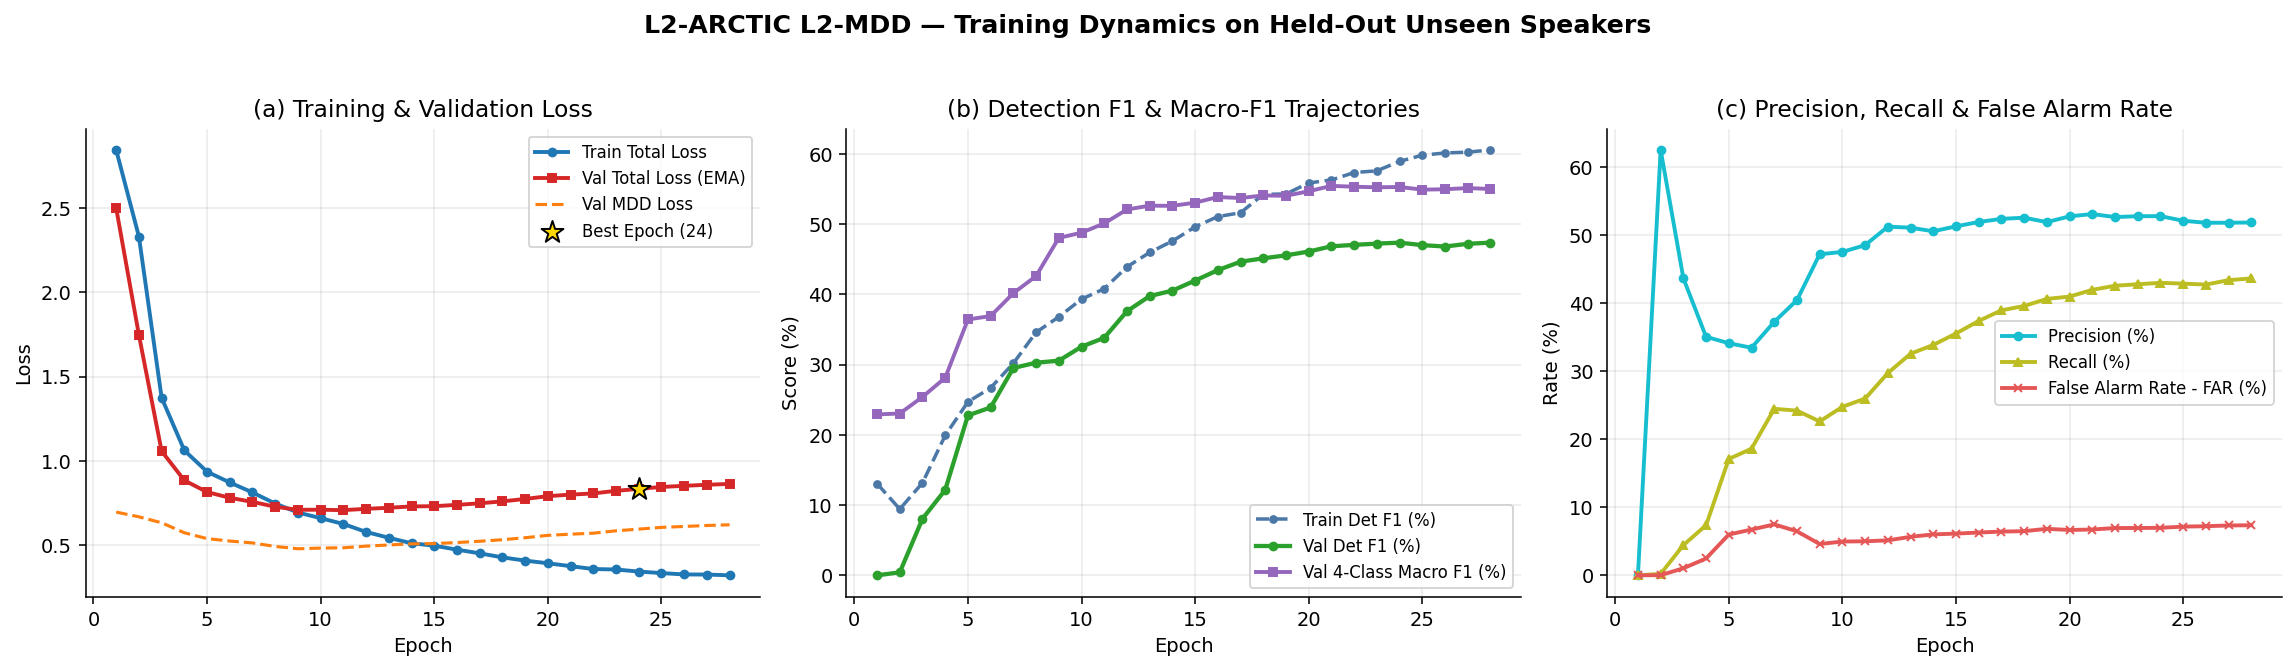

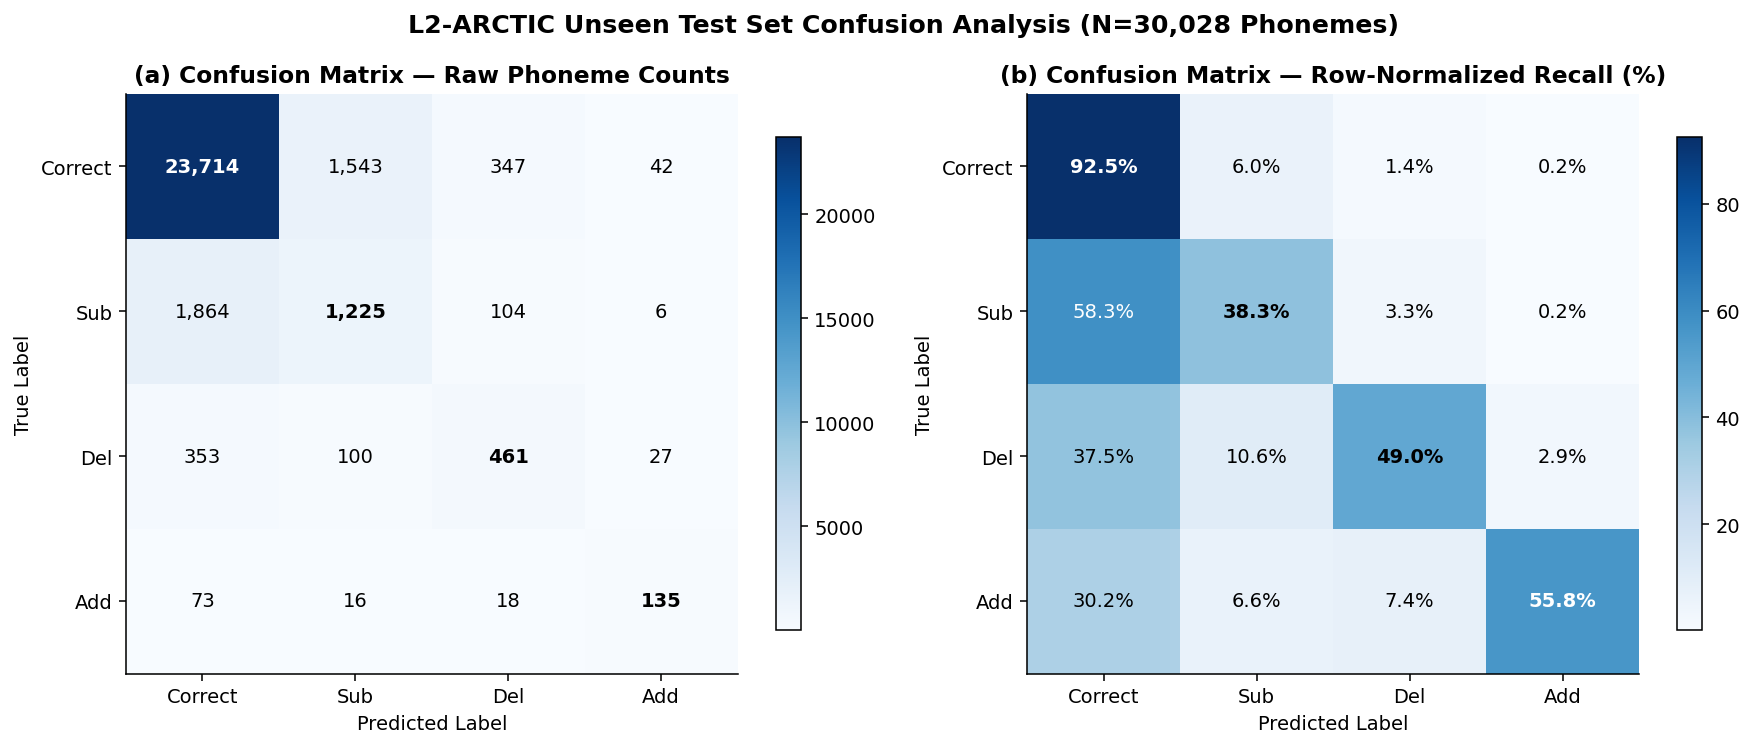

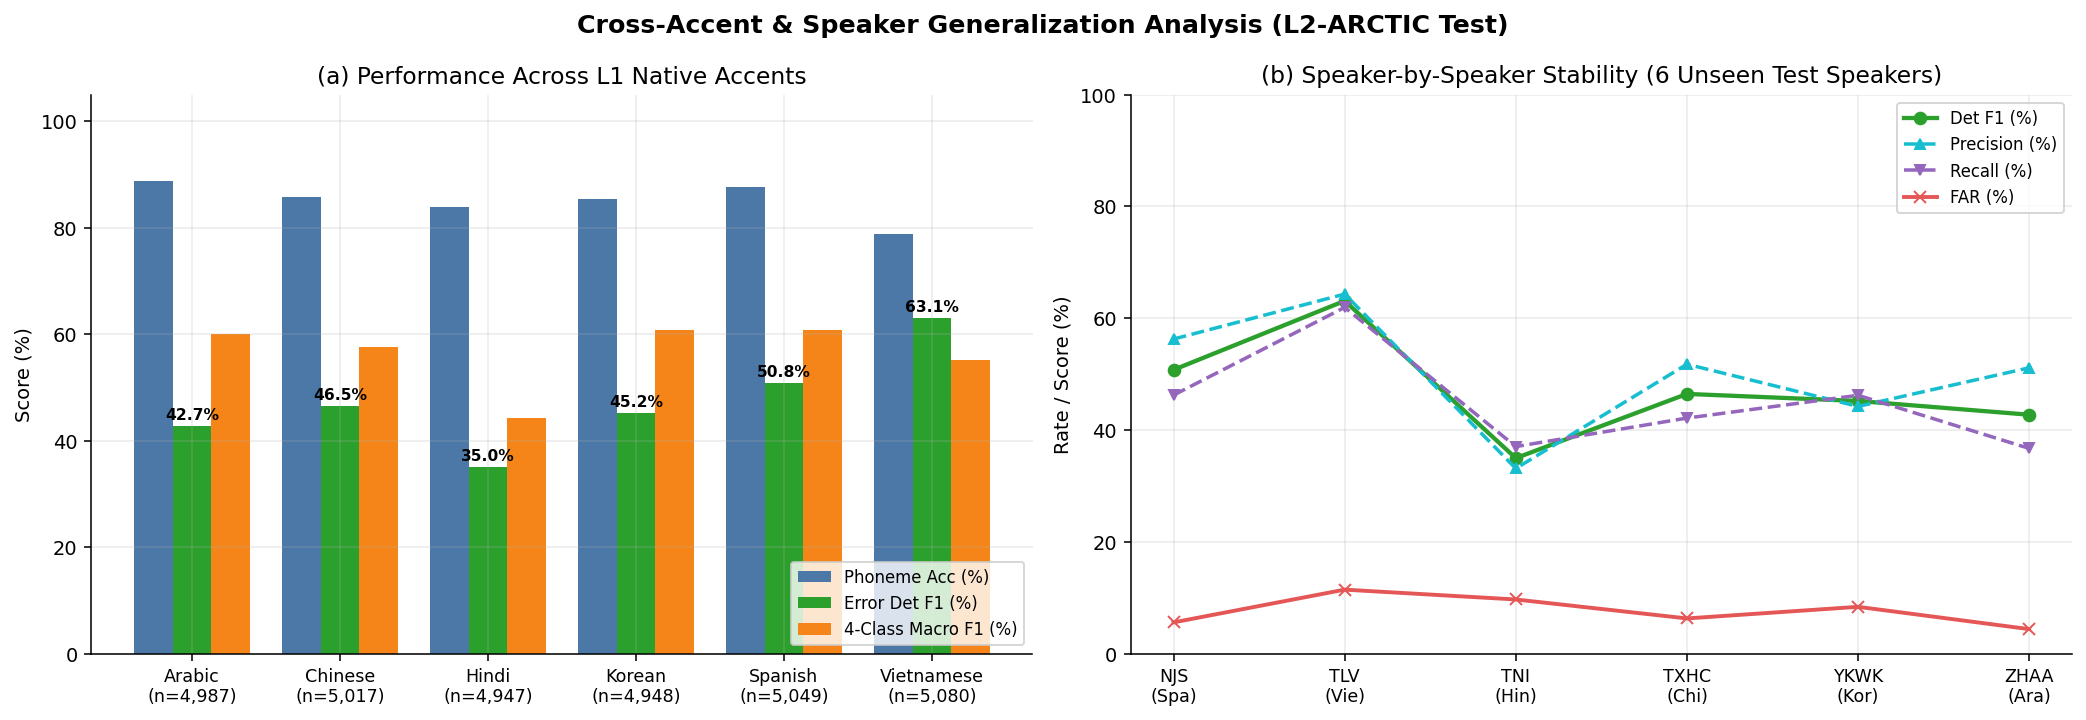

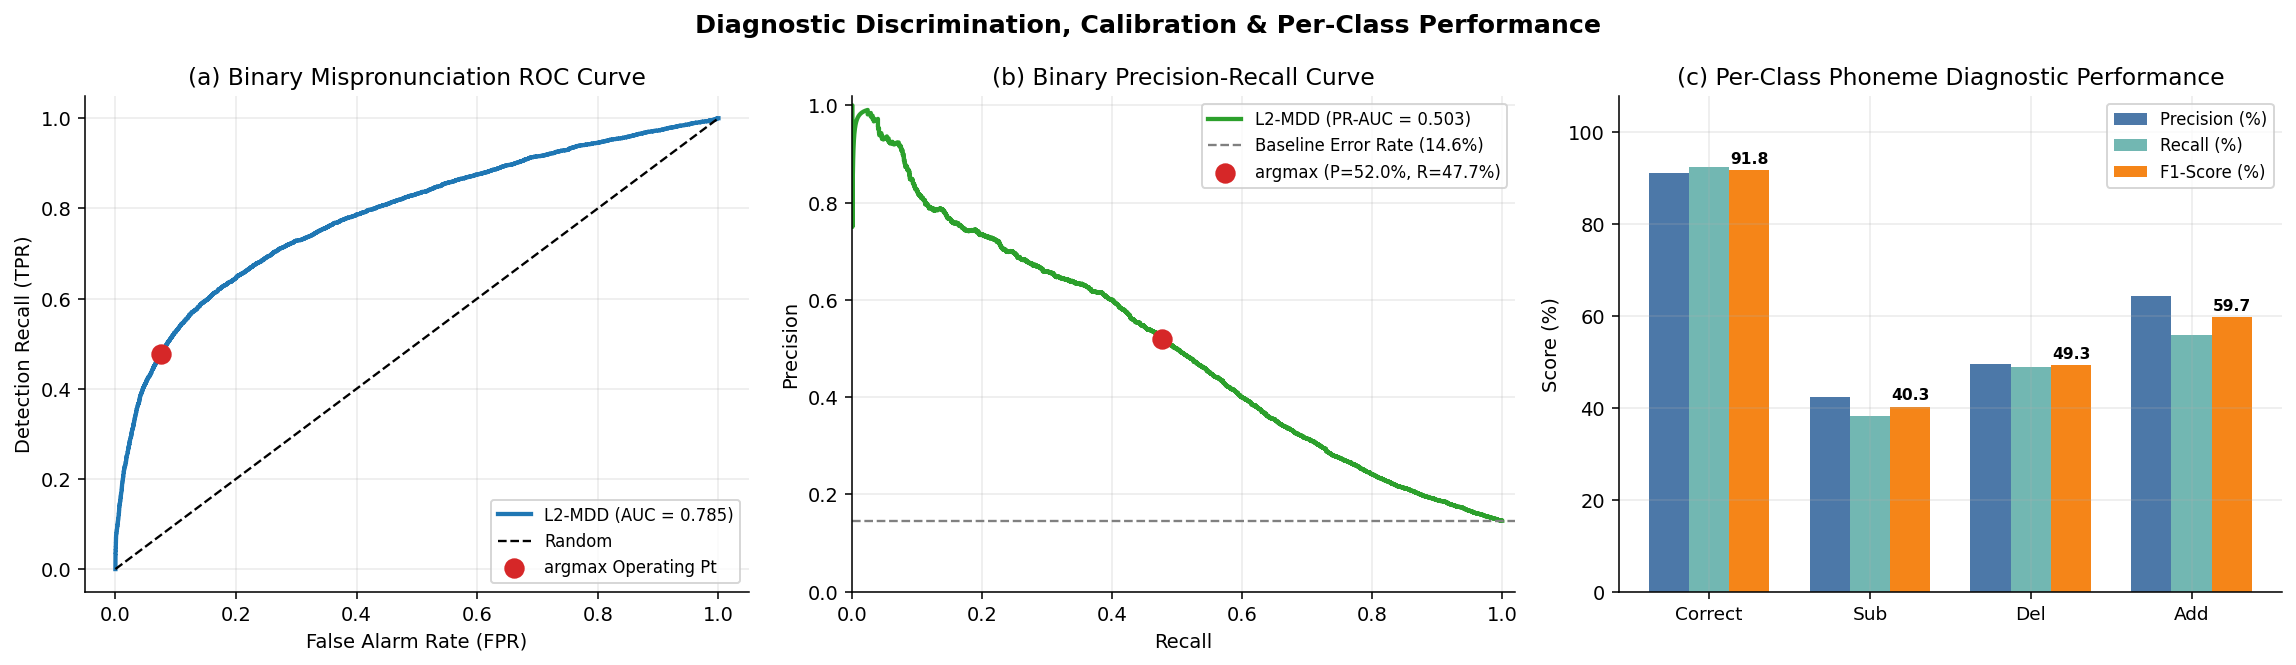


📁 Thesis reports & 300-DPI figures saved to: /kaggle/working/reports_l2_mdd

📦 Output files in /kaggle/working:
  - /kaggle/working/__notebook__.ipynb (4.13 MB)
  - /kaggle/working/l2_mdd_best.pt (1324.87 MB)
  - /kaggle/working/reports_l2_mdd/fig1_training_curves_l2_mdd.png (0.42 MB)
  - /kaggle/working/reports_l2_mdd/fig2_confusion_matrices_l2_mdd.png (0.25 MB)
  - /kaggle/working/reports_l2_mdd/fig3_l1_accent_and_speaker_breakdown.png (0.34 MB)
  - /kaggle/working/reports_l2_mdd/fig4_roc_pr_and_class_metrics.png (0.34 MB)
  - /kaggle/working/reports_l2_mdd/per_class_metrics.csv (0.00 MB)
  - /kaggle/working/reports_l2_mdd/per_l1_metrics.csv (0.00 MB)
  - /kaggle/working/reports_l2_mdd/per_speaker_metrics.csv (0.00 MB)
  - /kaggle/working/reports_l2_mdd/summary_metrics.json (0.00 MB)
  - /kaggle/working/reports_l2_mdd/threshold_sensitivity.csv (0.00 MB)
  - /kaggle/working/reports_l2_mdd/training_history.csv (0.01 MB)


In [5]:
import os, torch
from pathlib import Path

os.environ.setdefault("PYTORCH_ALLOC_CONF", "expandable_segments:True")
os.makedirs("/kaggle/working/hf_cache", exist_ok=True)
os.environ["HF_HOME"] = "/kaggle/working/hf_cache"

assert torch.cuda.is_available(), "Settings -> Accelerator -> GPU T4"
torch.cuda.empty_cache()

data_dir = prepare_l2_arctic_dir()
CONFIG["train"]["dataset"]["data_dir"] = str(data_dir)
ok, issues, info = verify_l2_arctic(data_dir)
print("Dataset:", info)
if not ok:
    raise RuntimeError("\n".join(issues))

trainer = MDDTrainer(CONFIG)
trainer.train()

print("\n" + "=" * 86)
print("🎯 RUNNING FINAL ISOLATED TEST EVALUATION & GENERATING THESIS CHARTS...")
print("=" * 86)
summary = trainer.evaluate_test_set()

print("\n📦 Output files in /kaggle/working:")
for p in sorted(Path("/kaggle/working").rglob("*")):
    if p.is_file() and "hf_cache" not in str(p):
        print(f"  - {p} ({p.stat().st_size / (1024**2):.2f} MB)")
